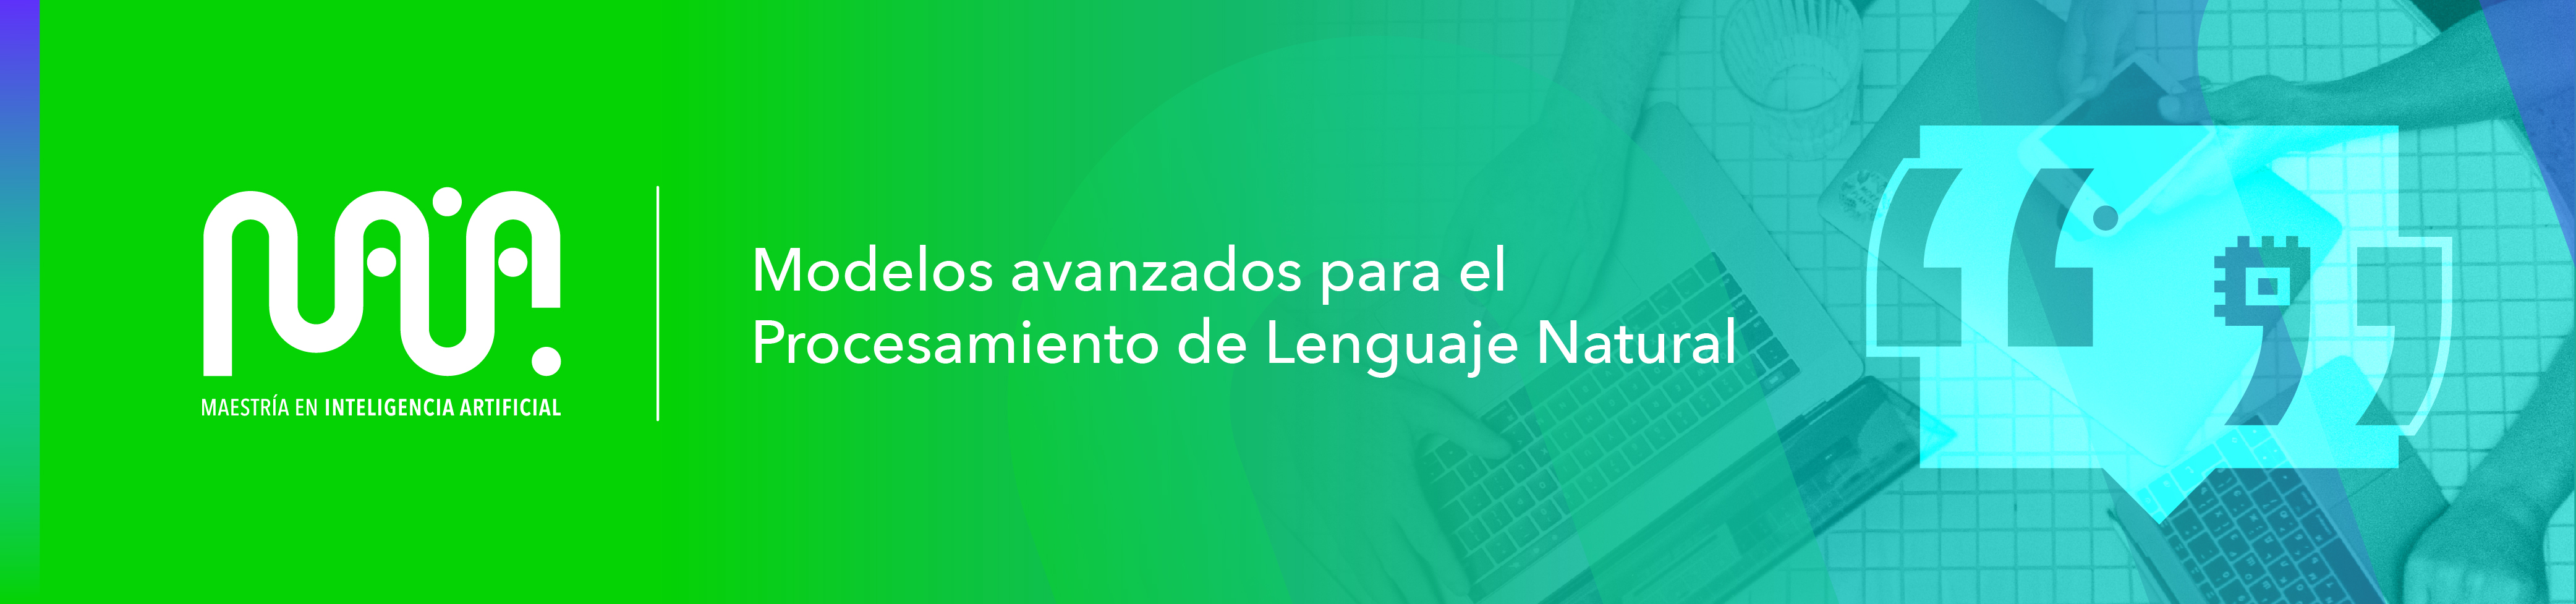


# 1. Portada e introducción

**Micro proyecto 1 — Generación de bocetos (Sketch-RNN)**
Curso: Modelos Avanzados de Procesamiento de Lenguaje Natural — MAIA

- **Estudiante:** Maria Fernanda Hurtado, Johana Nataly Tinoco, Ivan Eduardo Rincon, Zenon Jorge Alano, Luisa Aristizabal.
- **Categoría seleccionada:** `apple` (manzana)

## Resumen del proyecto

Se entrena desde cero, en PyTorch, un modelo recurrente capaz de **generar bocetos nuevos de manzanas**
a partir de los dibujos de la categoría `apple` del dataset *Quick, Draw!* (versión sketch-rnn).
Cada boceto es una secuencia de movimientos del lápiz; el modelo recibe los puntos anteriores y predice el
siguiente punto, compuesto por dos salidas numéricas (Δx, Δy) y una salida categórica (`pen_state`, 3 clases).

Se respetan los límites obligatorios: **16.000 / 2.000 / 2.000** bocetos (train / validación / prueba, tomados de
los conjuntos del `.npz`) y **máximo 200 puntos por boceto**. El relleno (*padding*) se enmascara tanto en la
pérdida como en las métricas. Sobre el conjunto de prueba se reportan el **MSE** de Δx y Δy, el **F1 macro** de
`pen_state` y el valor de la **función de pérdida**, y se generan bocetos completos guardados como PNG.

## Diagrama de la arquitectura

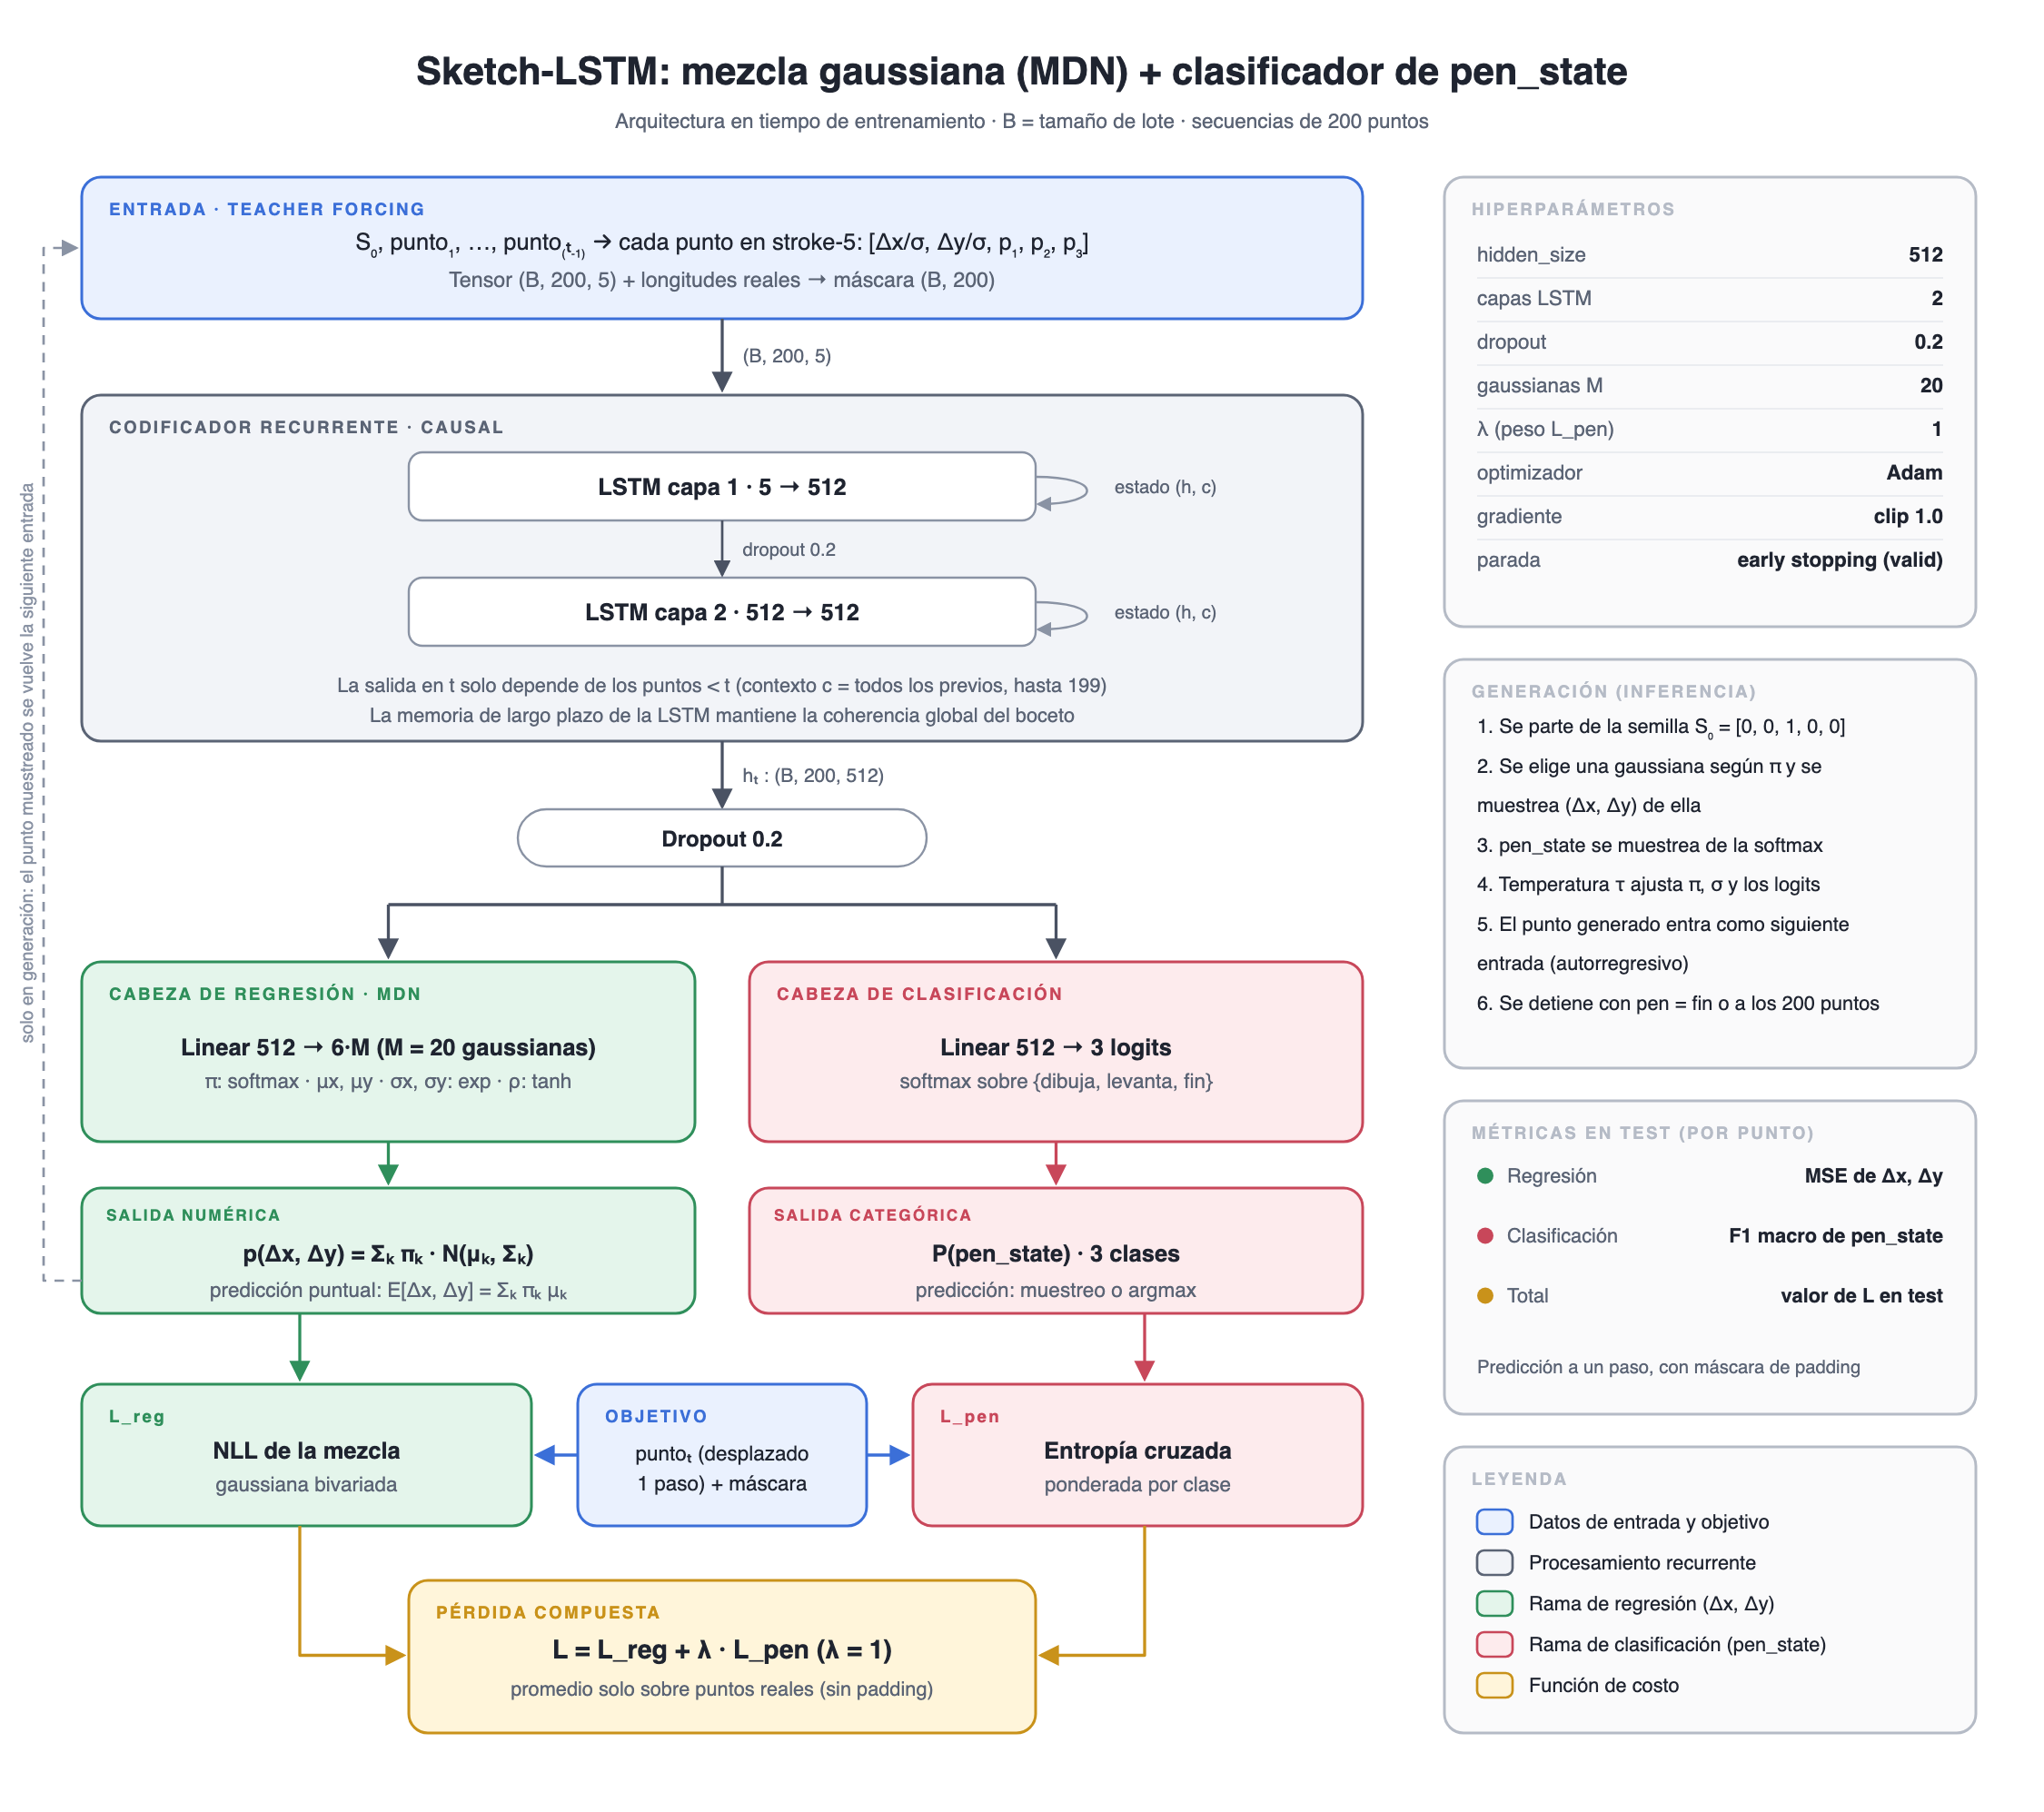

_Fuente vectorial del diagrama: `diagrama_arquitectura.svg` (también entregado por aparte junto con el PNG)._

## Explicación de la arquitectura

1. **Entrada.** Cada punto se representa en formato *stroke-5*: `[Δx/σx, Δy/σy, p1, p2, p3]`, donde Δx y Δy están
   normalizados por su desviación estándar (calculada sólo sobre entrenamiento) y `(p1, p2, p3)` es el *one-hot*
   de `pen_state` (dibuja / levanta el lápiz / fin del dibujo). La secuencia de entrada es
   `[S0, punto_1, …, punto_199]`, donde `S0 = (0, 0, 1, 0, 0)` es un token de inicio, y el objetivo es la misma
   secuencia desplazada un paso: `[punto_1, …, punto_200]` (*teacher forcing*). El lote tiene forma `(B, 200, 5)`
   y viene acompañado de una máscara `(B, 200)` que marca los puntos reales.
2. **Codificador recurrente.** Una **LSTM de 2 capas con 512 unidades** (dropout 0.2 entre capas) recorre la
   secuencia. Por ser causal, el estado oculto en el paso *t* resume **todos** los puntos anteriores
   (contexto *c* = toda la historia, hasta 199 puntos), sin necesidad de fijar una ventana.
3. **Cabeza de regresión (Δx, Δy) — red de densidad de mezcla (MDN).** Una capa `Linear(512 → 6·M)` con
   **M = 20** componentes produce, para cada paso, los parámetros de una mezcla de gaussianas bivariadas:
   pesos π (softmax), medias μx, μy, desviaciones σx, σy (exponencial, para que sean positivas) y correlación ρ
   (tanh, para que esté en (−1, 1)). La salida numérica puntual del modelo es el valor esperado
   E[Δx, Δy] = Σ πk μk, y la generación usa esa media (con la opción de muestrear de la mezcla
   para obtener diversidad).
4. **Cabeza de clasificación (`pen_state`).** Una capa `Linear(512 → 3)` produce los *logits* de los 3 estados.
5. **Pérdida compuesta.** `L = L_reg + λ·L_pen` con λ = 1:
   - `L_reg`: log-verosimilitud negativa (NLL) de (Δx, Δy) reales bajo la mezcla — componente de regresión
     probabilística.
   - `L_pen`: entropía cruzada de `pen_state`, ponderada por clase porque las clases están muy desbalanceadas
     (≈ 90 % "dibuja", ≈ 7 % "levanta", ≈ 3 % "fin").
   - Ambas se promedian **sólo sobre los puntos reales** (máscara).

## Justificación de la selección

- **LSTM y no RNN simple:** los bocetos tienen en promedio ~100 puntos y la forma global (p. ej. cerrar el cuerpo,
  volver a dibujar las patas) depende de lo dibujado muchos pasos atrás. Las compuertas de la LSTM mitigan el
  desvanecimiento del gradiente y retienen esa memoria de largo plazo; es la misma elección del decodificador de
  Sketch-RNN (Ha & Eck, 2017).
- **Mezcla de gaussianas y no un único valor:** el siguiente trazo es **multimodal** (desde un mismo punto el
  dibujante puede ir a la izquierda o a la derecha) y el EDA mostró dos regímenes de movimiento (pasos cortos dentro
  de un trazo y saltos grandes al levantar el lápiz). Una regresión con MSE sólo aprende la media de esas opciones;
  la MDN modela la distribución completa, y por eso se entrena con la NLL de la mezcla. Al generar se usa el valor
  esperado de la mezcla, que además es la predicción óptima en MSE, por lo que la métrica obligatoria se calcula
  sobre la misma salida. Muestrear de la mezcla da más variedad, pero en esta categoría produjo líneas quebradas
  (ver sección 9).
- **Cabeza categórica separada con pesos de clase:** `pen_state` es una variable discreta y el estado "fin" es muy
  poco frecuente; sin ponderación el modelo tendería a no predecirlo nunca (F1 macro bajo y bocetos que no terminan).
- **Tamaño (2×512, ~3,2 M parámetros):** suficiente capacidad para 16.000 secuencias, entrenable en minutos en una GPU,
  y controlado contra el sobreajuste con dropout, aumento de datos (escalado aleatorio), recorte de gradiente,
  *weight decay* y *early stopping* sobre validación.

# 2. Librerías

In [1]:
import math
import random
import urllib.request
from collections.abc import Sequence
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Any, NamedTuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from matplotlib.axes import Axes
from matplotlib.colors import LogNorm
from scipy import stats
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    classification_report,
    confusion_matrix,
    f1_score,
)
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)  # noqa: NPY002 -- el estado global de numpy se fija igual que el de torch
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
# Reproducibilidad estricta en CUDA a cambio de algo de velocidad.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# Dispositivo de cómputo: GPU (CUDA o Apple MPS) si está disponible, de lo contrario CPU
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("PyTorch", torch.__version__, "| dispositivo:", device)

PyTorch 2.13.0+cu132 | dispositivo: cuda


# 3. Lectura del dataset y exploración

Se descarga el archivo `.npz` de la categoría `apple` (versión sketch-rnn, ya simplificada con RDP y dividida
en train / valid / test). Cada boceto está en formato *stroke-3*: `(Δx, Δy, pen_lift)`, donde `pen_lift = 1`
indica que el lápiz se levanta después del punto (fin de un trazo).

In [2]:
CATEGORY = "apple"
MAX_LEN = 200  # límite obligatorio: puntos por boceto
N_TRAIN, N_VALID, N_TEST = 16_000, 2_000, 2_000  # split obligatorio 80 / 10 / 10

DATA_DIR = Path("artifacts")  # el .npz se reutiliza si ya está descargado
OUT_DIR = Path("salidas")  # única carpeta de artefactos del notebook
OUT_DIR.mkdir(parents=True, exist_ok=True)

# Columnas del formato stroke-3: (Δx, Δy, pen_lift)
DX_COL = 0
DY_COL = 1
PEN_LIFT_COL = 2
DELTA_XY_SLICE = slice(DX_COL, DY_COL + 1)
PEN_LIFT_CONTINUE = 0
PEN_LIFT_END = 1

url = f"https://storage.googleapis.com/quickdraw_dataset/sketchrnn/{CATEGORY}.npz"
npz_path = DATA_DIR / f"{CATEGORY}.npz"
if not npz_path.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve(url, npz_path)

# En Python 3 se debe cargar con encoding='latin1' y allow_pickle=True
with np.load(npz_path, encoding="latin1", allow_pickle=True) as data:
    raw_train, raw_valid, raw_test = data["train"], data["valid"], data["test"]

print(
    "Tamaños originales -> train:",
    len(raw_train),
    "| valid:",
    len(raw_valid),
    "| test:",
    len(raw_test),
)

sketch = raw_train[0]
print("Forma del primer dibujo:", sketch.shape, "| dtype:", sketch.dtype)
print(sketch[:5])

Tamaños originales -> train: 70000 | valid: 2500 | test: 2500
Forma del primer dibujo: (43, 3) | dtype: int16
[[-17 -18   0]
 [-19 -14   0]
 [-32  -2   0]
 [-13   5   0]
 [-17  11   0]]


Longitud -> media: 37.9 | mediana: 37 | p95: 55 | máx: 62
Bocetos con más de 200 puntos: 0.00%
Δx -> media 0.74, desv. 27.69, rango [-982, 1322]
Δy -> media -1.62, desv. 32.52, rango [-730, 645]
Proporción de puntos con pen_lift = 1 (fin de trazo): 7.2%


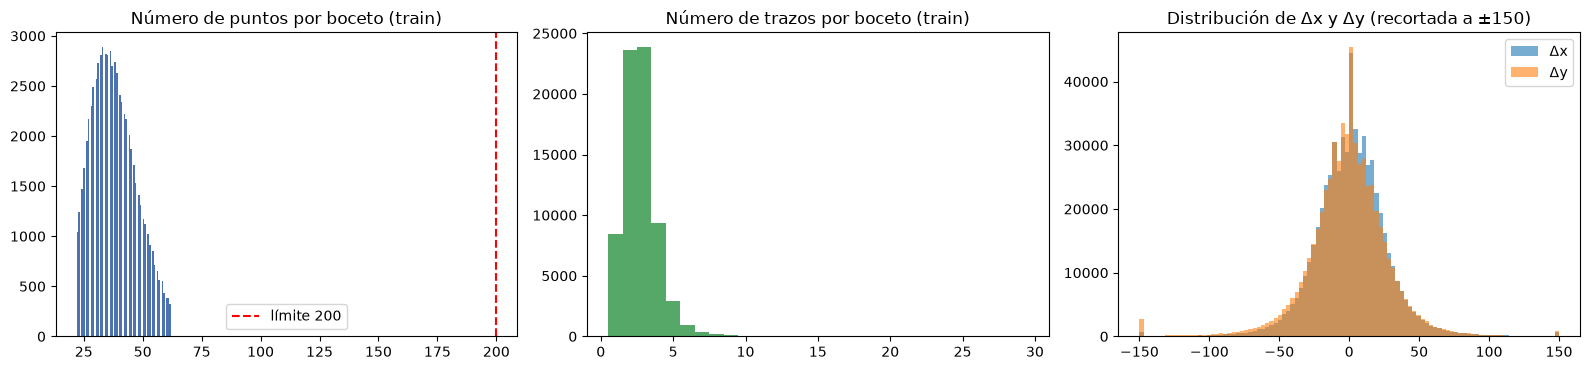

In [3]:
# Las longitudes se describen sobre todo el conjunto provisto; los análisis siguientes
# usan los primeros N_TRAIN bocetos, que son los del split obligatorio.
lengths = np.array([len(s) for s in raw_train])
all_pts = np.concatenate(raw_train[:N_TRAIN]).astype(np.float64)

P95_PERCENTILE = 95
MAX_STROKES_SHOWN = 30
DELTA_DISPLAY_LIMIT = 150

print(
    f"Longitud -> media: {lengths.mean():.1f} | mediana: {np.median(lengths):.0f} | "
    f"p95: {np.percentile(lengths, P95_PERCENTILE):.0f} | máx: {lengths.max()}"
)
print(f"Bocetos con más de {MAX_LEN} puntos: {(lengths > MAX_LEN).mean() * 100:.2f}%")
delta_x, delta_y = all_pts[:, DX_COL], all_pts[:, DY_COL]
print(
    f"Δx -> media {delta_x.mean():.2f}, desv. {delta_x.std():.2f}, "
    f"rango [{delta_x.min():.0f}, {delta_x.max():.0f}]"
)
print(
    f"Δy -> media {delta_y.mean():.2f}, desv. {delta_y.std():.2f}, "
    f"rango [{delta_y.min():.0f}, {delta_y.max():.0f}]"
)
print(
    f"Proporción de puntos con pen_lift = {PEN_LIFT_END} (fin de trazo): "
    f"{all_pts[:, PEN_LIFT_COL].mean() * 100:.1f}%"
)

n_strokes = np.array([s[:, PEN_LIFT_COL].sum() for s in raw_train])
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
axes[0].hist(lengths, bins=60, color="#4c72b0")
axes[0].axvline(MAX_LEN, color="red", ls="--", label=f"límite {MAX_LEN}")
axes[0].set_title("Número de puntos por boceto (train)")
axes[0].legend()
axes[1].hist(n_strokes, bins=np.arange(0.5, MAX_STROKES_SHOWN + 0.5), color="#55a868")
axes[1].set_title("Número de trazos por boceto (train)")
axes[2].hist(
    np.clip(delta_x, -DELTA_DISPLAY_LIMIT, DELTA_DISPLAY_LIMIT), bins=100, alpha=0.6, label="Δx"
)
axes[2].hist(
    np.clip(delta_y, -DELTA_DISPLAY_LIMIT, DELTA_DISPLAY_LIMIT), bins=100, alpha=0.6, label="Δy"
)
axes[2].set_title(f"Distribución de Δx y Δy (recortada a ±{DELTA_DISPLAY_LIMIT})")
axes[2].legend()
plt.tight_layout()
plt.show()

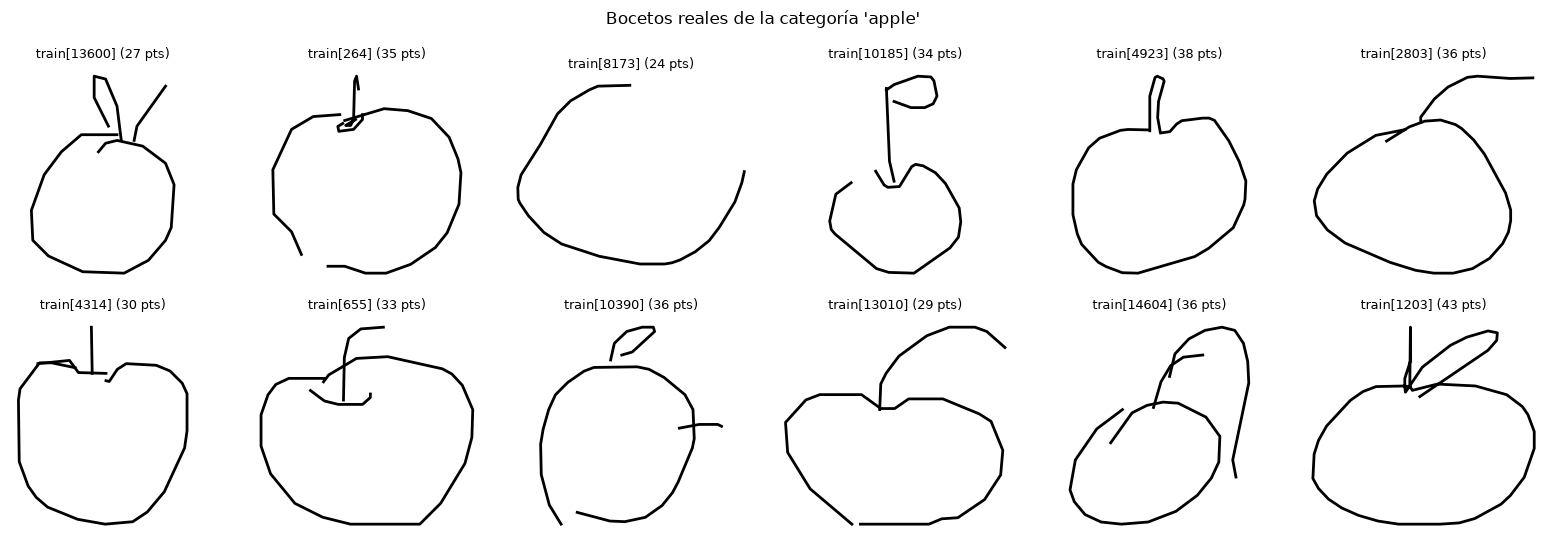

In [4]:
FIGURE_DPI = 120
SAMPLE_SEED = 0
N_SAMPLE_ROWS, N_SAMPLE_COLS = 2, 6
N_SAMPLES = N_SAMPLE_ROWS * N_SAMPLE_COLS


def draw_sketch(ax: Axes, sketch: np.ndarray, color: str = "black", lw: float = 2) -> None:
    """Dibuja un boceto stroke-3 (dx, dy, pen_lift) en unos ejes de matplotlib."""
    sketch = np.asarray(sketch, dtype=np.float64)
    coords = np.cumsum(sketch[:, DELTA_XY_SLICE], axis=0)  # desplazamientos -> posiciones absolutas
    start = 0
    for i in range(len(sketch)):
        # fin de un trazo (o último punto)
        if sketch[i, PEN_LIFT_COL] == PEN_LIFT_END or i == len(sketch) - 1:
            ax.plot(
                coords[start : i + 1, DX_COL],
                -coords[start : i + 1, DY_COL],
                color=color,
                linewidth=lw,
            )
            start = i + 1
    ax.set_aspect("equal")
    ax.axis("off")


def render_sketch(sketch: np.ndarray, filename: str | Path) -> None:
    """Renderiza un boceto stroke-3 y lo guarda como PNG."""
    fig, ax = plt.subplots(figsize=(4, 4))
    draw_sketch(ax, sketch)
    fig.savefig(filename, bbox_inches="tight", dpi=FIGURE_DPI)
    plt.close(fig)


rng_samples = np.random.default_rng(SAMPLE_SEED)
sample_ids = rng_samples.choice(N_TRAIN, N_SAMPLES, replace=False)

fig, axes = plt.subplots(N_SAMPLE_ROWS, N_SAMPLE_COLS, figsize=(16, 5.5))
for ax, idx in zip(axes.ravel(), sample_ids, strict=True):
    draw_sketch(ax, raw_train[idx])
    ax.set_title(f"train[{idx}] ({len(raw_train[idx])} pts)", fontsize=9)
plt.suptitle(f"Bocetos reales de la categoría '{CATEGORY}'")
plt.tight_layout()
plt.show()
render_sketch(raw_train[0], OUT_DIR / "ejemplo_real.png")

## 3.1 Análisis que justifican el diseño del modelo

In [5]:
# Datos de exploración: los N_TRAIN bocetos de entrenamiento, truncados a 199 puntos
# reales (como en el modelo).
EDA_MAX_POINTS = MAX_LEN - 1
N_DELTA_DIMENSIONS = 2

eda_sk = [s[:EDA_MAX_POINTS].astype(np.float64) for s in raw_train[:N_TRAIN]]
pts = np.concatenate(eda_sk)
sd_x, sd_y = pts[:, DX_COL].std(), pts[:, DY_COL].std()
zx = pts[:, DX_COL] / sd_x  # Δx normalizado
zy = pts[:, DY_COL] / sd_y  # Δy normalizado
pos = np.concatenate([np.arange(len(s)) for s in eda_sk])  # índice del punto en su boceto
n_pts = np.concatenate([np.full(len(s), len(s)) for s in eda_sk])  # longitud del boceto
prev_lift = np.concatenate(
    [np.r_[np.nan, s[:-1, PEN_LIFT_COL]] for s in eda_sk]
)  # pen_lift anterior
lens_eda = np.array([len(s) for s in eda_sk])
strokes_eda = np.array([s[:, PEN_LIFT_COL].sum() for s in eda_sk])
print(f"{len(eda_sk):,} bocetos | {len(pts):,} puntos | σx = {sd_x:.2f} px | σy = {sd_y:.2f} px")

16,000 bocetos | 607,404 puntos | σx = 27.69 px | σy = 32.52 px


### a) Dos regímenes de movimiento y colas pesadas

Se compara la distribución de (Δx, Δy) en dos situaciones: **dentro de un trazo** (el punto anterior seguía en el
papel) y en el **primer punto después de levantar el lápiz** (el salto hacia donde empieza el trazo siguiente). Si los
dos regímenes tienen escalas muy distintas, una única gaussiana, o una regresión con MSE que sólo aprende la media,
no puede describir ambos a la vez. Una **mezcla de gaussianas** sí puede: dedica componentes estrechas a los
movimientos cortos dentro de los trazos y componentes anchas a los saltos entre trazos.

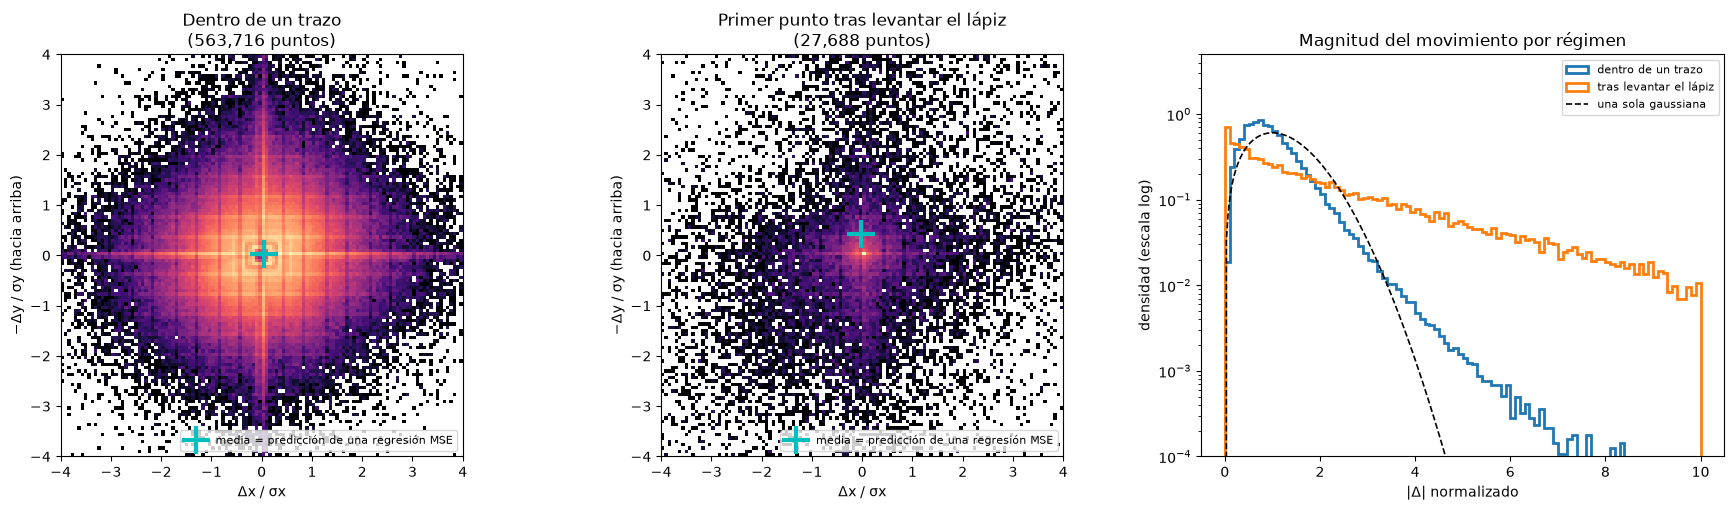

dentro de un trazo      :  92.8 % de los puntos | varianza media de Δ normalizado = 0.75
tras levantar el lápiz  :   4.6 % de los puntos | varianza media de Δ normalizado = 6.16
Los saltos tras levantar el lápiz son 4.7 % de los puntos pero aportan 28.7 % del error cuadrático de una predicción constante.


In [6]:
mid = prev_lift == PEN_LIFT_CONTINUE  # continuación de un trazo (el primer punto no tiene anterior)
after = prev_lift == PEN_LIFT_END  # primer punto tras levantar el lápiz
DISPLAY_LIMIT = 4
MAGNITUDE_PLOT_MAX = 10
DENSITY_GRID_POINTS = 300

fig = plt.figure(figsize=(18, 5.2))
regimes = [
    (mid, "Dentro de un trazo", "dentro de un trazo"),
    (after, "Primer punto tras levantar el lápiz", "tras levantar el lápiz"),
]
n_plot_axes = len(regimes) + 1
for i, (mask, title, _) in enumerate(regimes):
    ax = fig.add_subplot(1, n_plot_axes, i + 1)
    ax.hist2d(
        zx[mask],
        -zy[mask],
        bins=120,
        range=[[-DISPLAY_LIMIT, DISPLAY_LIMIT], [-DISPLAY_LIMIT, DISPLAY_LIMIT]],
        cmap="magma",
        norm=LogNorm(),
    )
    ax.plot(
        zx[mask].mean(),
        -zy[mask].mean(),
        "c+",
        ms=20,
        mew=3,
        label="media = predicción de una regresión MSE",
    )
    ax.set_title(f"{title}\n({mask.sum():,} puntos)")
    ax.set_xlabel("Δx / σx")
    ax.set_ylabel("−Δy / σy (hacia arriba)")
    ax.set_aspect("equal")
    ax.legend(loc="lower right", fontsize=8)
ax = fig.add_subplot(1, n_plot_axes, n_plot_axes)
grid = np.linspace(0, MAGNITUDE_PLOT_MAX, DENSITY_GRID_POINTS)
r_all = np.hypot(zx, zy)
for mask, _, label in regimes:
    ax.hist(
        r_all[mask],
        bins=100,
        range=(0, MAGNITUDE_PLOT_MAX),
        density=True,
        histtype="step",
        lw=2,
        label=label,
    )
sigma_all = np.sqrt((r_all**2).mean() / N_DELTA_DIMENSIONS)  # gaussiana isotrópica única
ax.plot(grid, stats.rayleigh.pdf(grid, scale=sigma_all), "k--", lw=1.2, label="una sola gaussiana")
ax.set_yscale("log")
ax.set_ylim(1e-4, 5)
ax.set_xlabel("|Δ| normalizado")
ax.set_ylabel("densidad (escala log)")
ax.set_title("Magnitud del movimiento por régimen")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Cuánto del error cuadrático de una predicción constante (la media de cada grupo)
# aportan los saltos entre trazos.
for mask, _, label in regimes:
    var = (
        (zx[mask] - zx[mask].mean()) ** 2 + (zy[mask] - zy[mask].mean()) ** 2
    ).mean() / N_DELTA_DIMENSIONS
    print(
        f"{label:<24}: {mask.mean() * 100:5.1f} % de los puntos | "
        f"varianza media de Δ normalizado = {var:.2f}"
    )
sq_mid = ((zx[mid] - zx[mid].mean()) ** 2 + (zy[mid] - zy[mid].mean()) ** 2).sum()
sq_after = ((zx[after] - zx[after].mean()) ** 2 + (zy[after] - zy[after].mean()) ** 2).sum()
print(
    f"Los saltos tras levantar el lápiz son {after.sum() / (mid.sum() + after.sum()) * 100:.1f} % de los puntos "
    f"pero aportan {sq_after / (sq_mid + sq_after) * 100:.1f} % del error cuadrático de una predicción constante."
)

### b) Colas pesadas y valores atípicos de Δ 

Una distribución normal tiene curtosis en exceso 0 y prácticamente ningún valor más allá de 5σ. Se cuantifica qué
tan lejos están Δx y Δy de ese comportamiento y cuántos saltos extremos hay. Sketch-RNN original recorta los
desplazamientos a ±1000 px; aquí sólo se reporta, sin filtrar (el límite de 16.000 bocetos se respeta tal cual).

,desv. est. (px),mediana |Δ| (px),p99 |Δ| (px),p99.9 |Δ| (px),máx |Δ| (px),máx |Δ| (en σ),curtosis en exceso,% |Δ| > 5σ,% |Δ| > 10σ
Δx,27.69,15.00,90.00,183.00,1322.00,47.75,31.70,0.25,0.02
Δy,32.52,15.00,114.00,273.00,730.00,22.45,21.69,0.48,0.04


Bocetos con algún desplazamiento > 1000 px (recorte de Sketch-RNN): 1 de 16,000


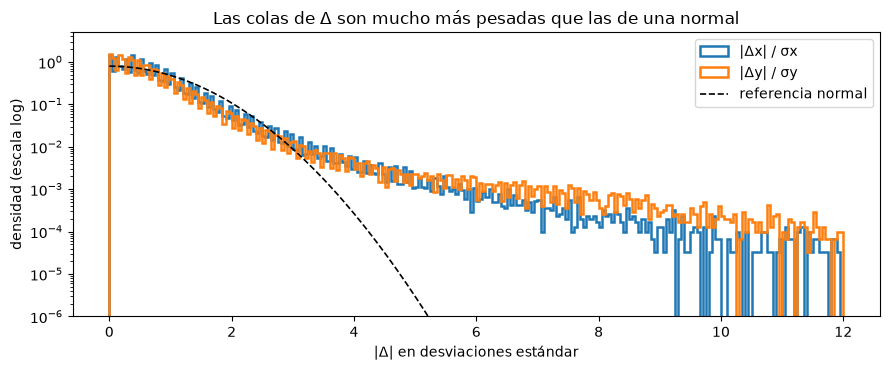

In [7]:
rows: dict[str, dict[str, float]] = {}
TAIL_PERCENTILES = (99, 99.9)
TAIL_SIGMAS = (5, 10)
TAIL_PLOT_MAX = 12
SKETCH_RNN_CLIP = 1000  # recorte de desplazamientos del Sketch-RNN original

for name, values, sd in [("Δx", pts[:, DX_COL], sd_x), ("Δy", pts[:, DY_COL], sd_y)]:
    abs_values = np.abs(values)
    rows[name] = {
        "desv. est. (px)": sd,
        "mediana |Δ| (px)": np.median(abs_values),
        "p99 |Δ| (px)": np.percentile(abs_values, TAIL_PERCENTILES[0]),
        "p99.9 |Δ| (px)": np.percentile(abs_values, TAIL_PERCENTILES[1]),
        "máx |Δ| (px)": abs_values.max(),
        "máx |Δ| (en σ)": abs_values.max() / sd,
        "curtosis en exceso": stats.kurtosis(values),
        f"% |Δ| > {TAIL_SIGMAS[0]}σ": (abs_values > TAIL_SIGMAS[0] * sd).mean() * 100,
        f"% |Δ| > {TAIL_SIGMAS[1]}σ": (abs_values > TAIL_SIGMAS[1] * sd).mean() * 100,
    }
display(
    pd.DataFrame(rows)
    .T.style.format("{:.2f}")
    .set_caption("Colas de la distribución de Δ (entrenamiento)")
)
n_big = sum(np.abs(s[:, DELTA_XY_SLICE]).max() > SKETCH_RNN_CLIP for s in eda_sk)
print(
    f"Bocetos con algún desplazamiento > {SKETCH_RNN_CLIP} px "
    f"(recorte de Sketch-RNN): {n_big} de {N_TRAIN:,}"
)

fig, ax = plt.subplots(figsize=(9, 3.8))
grid = np.linspace(0, TAIL_PLOT_MAX, DENSITY_GRID_POINTS)
ax.hist(
    np.abs(zx),
    bins=240,
    range=(0, TAIL_PLOT_MAX),
    density=True,
    histtype="step",
    lw=1.8,
    label="|Δx| / σx",
)
ax.hist(
    np.abs(zy),
    bins=240,
    range=(0, TAIL_PLOT_MAX),
    density=True,
    histtype="step",
    lw=1.8,
    label="|Δy| / σy",
)
ax.plot(grid, N_DELTA_DIMENSIONS * stats.norm.pdf(grid), "k--", lw=1.2, label="referencia normal")
ax.set_yscale("log")
ax.set_ylim(1e-6, 5)
ax.set_xlabel("|Δ| en desviaciones estándar")
ax.set_ylabel("densidad (escala log)")
ax.set_title("Las colas de Δ son mucho más pesadas que las de una normal")
ax.legend()
plt.tight_layout()
plt.show()

### c) Autocorrelación de Δ a lo largo del boceto 

Correlación entre el desplazamiento del punto *t* y el del punto *t − k*, juntando los pares de todos los bocetos.
Si los puntos consecutivos se parecen y la correlación decae lentamente, el pasado contiene información útil para
predecir el siguiente punto: es la justificación de usar una **LSTM con toda la historia como contexto**. Como
referencia se calcula lo mismo con el orden de los puntos barajado dentro de cada boceto (sin estructura temporal).

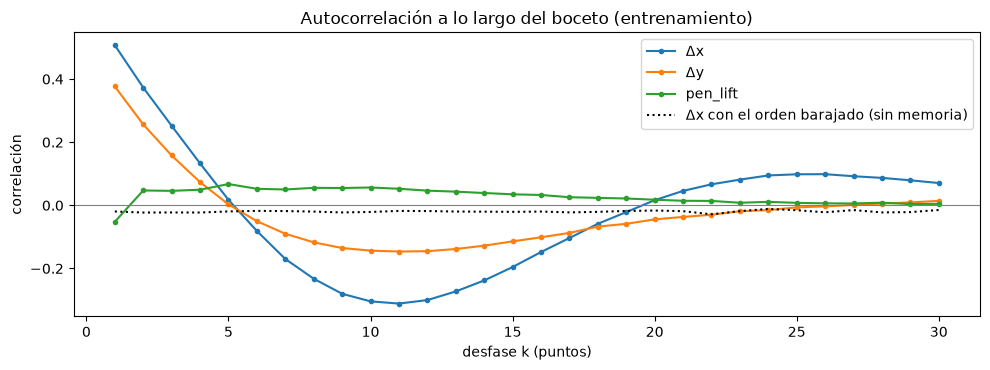

Δx        correlación con k=1: +0.507 | k=5: +0.017 | |r| < 0.1 desde k = 5
Δy        correlación con k=1: +0.377 | k=5: +0.003 | |r| < 0.1 desde k = 4
pen_lift  correlación con k=1: -0.052 | k=5: +0.067 | |r| < 0.1 desde k = 1


In [8]:
MAX_LAG = 30
CORR_OFF_DIAGONAL = (0, 1)
AUTOCORR_NEGLIGIBLE = 0.1
LAGS_TO_REPORT = (1, 5)
SHUFFLE_SEED = 0


def pooled_autocorr(
    sketches: Sequence[np.ndarray],
    col: int,
    max_lag: int = MAX_LAG,
) -> np.ndarray:
    """Correlación entre el valor en t y en t-k, juntando los pares de todas las secuencias."""
    out: list[float] = []
    for k in range(1, max_lag + 1):
        a = np.concatenate([s[:-k, col] for s in sketches if len(s) > k])
        b = np.concatenate([s[k:, col] for s in sketches if len(s) > k])
        out.append(float(np.corrcoef(a, b)[CORR_OFF_DIAGONAL]))
    return np.array(out)


lags = np.arange(1, MAX_LAG + 1)
rng_eda = np.random.default_rng(SHUFFLE_SEED)
shuffled = [s[rng_eda.permutation(len(s))] for s in eda_sk]
acf = {
    "Δx": pooled_autocorr(eda_sk, DX_COL),
    "Δy": pooled_autocorr(eda_sk, DY_COL),
    "pen_lift": pooled_autocorr(eda_sk, PEN_LIFT_COL),
}
acf_shuffled = pooled_autocorr(shuffled, DX_COL)

fig, ax = plt.subplots(figsize=(10, 3.8))
for name, values in acf.items():
    ax.plot(lags, values, "o-", ms=3, label=name)
ax.plot(lags, acf_shuffled, "k:", label="Δx con el orden barajado (sin memoria)")
ax.axhline(0, color="gray", lw=0.8)
ax.set_xlabel("desfase k (puntos)")
ax.set_ylabel("correlación")
ax.set_title("Autocorrelación a lo largo del boceto (entrenamiento)")
ax.legend()
plt.tight_layout()
plt.show()
for name, values in acf.items():
    below = np.flatnonzero(np.abs(values) < AUTOCORR_NEGLIGIBLE)
    first_negligible = lags[below[0]] if len(below) else f"> {MAX_LAG}"
    print(
        f"{name:<9} correlación con k={LAGS_TO_REPORT[0]}: "
        f"{values[LAGS_TO_REPORT[0] - 1]:+.3f} | "
        f"k={LAGS_TO_REPORT[1]}: {values[LAGS_TO_REPORT[1] - 1]:+.3f} | "
        f"|r| < {AUTOCORR_NEGLIGIBLE} desde k = {first_negligible}"
    )

### d) `pen_state` según la posición en el boceto 

La frecuencia global de cada estado (calculada como en el modelo, incluyendo el punto de fin) oculta que los estados
no se distribuyen de forma uniforme. Se muestra (i) la probabilidad de **levantar el lápiz** según la posición relativa
en el boceto, (ii) la **tasa de fin**: la probabilidad de que el dibujo termine en la posición *t* dado que llegó hasta
ahí, que es lo que el modelo debe aprender sin conocer la longitud total, y (iii) la frecuencia de cada clase junto
con los pesos ∝ 1/√frecuencia que usa la pérdida.

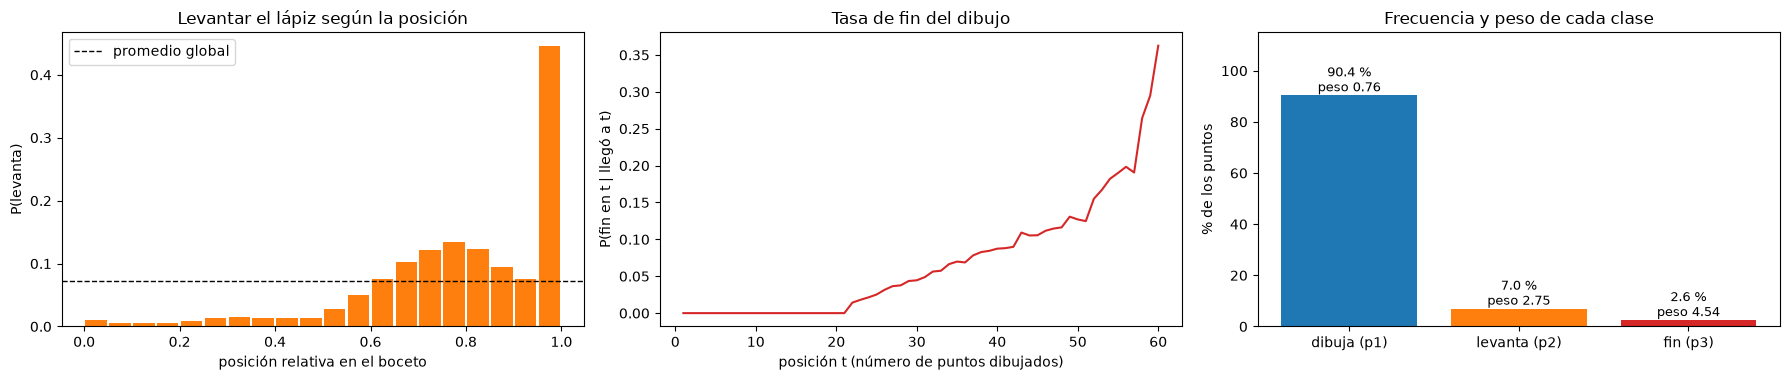

P(levanta) en el primer 10 % del boceto: 0.008 | en el último 10 %: 0.261
Tasa de fin máxima: 0.363 en t = 60 | mediana de la longitud: 37 puntos


In [9]:
NUM_PEN_STATES = 3
PEN_DRAW_CLASS = 0
PEN_LIFT_CLASS = 1
PEN_END_CLASS = 2
N_POSITION_BINS = 20
END_HAZARD_PERCENTILE = 99
CLASS_WEIGHT_POWER = -0.5

rel = pos / np.maximum(n_pts - 1, 1)
edges = np.linspace(0, 1, N_POSITION_BINS + 1)
bin_idx = np.clip(np.digitize(rel, edges) - 1, 0, N_POSITION_BINS - 1)
p_lift_rel = np.array([pts[bin_idx == b, PEN_LIFT_COL].mean() for b in range(N_POSITION_BINS)])

# Tasa de fin: el punto de fin ocupa la posición n (tras n puntos reales)
T_MAX = min(int(np.percentile(lens_eda, END_HAZARD_PERCENTILE)), EDA_MAX_POINTS - 1)
t_axis = np.arange(1, T_MAX + 1)
hazard = np.array([(lens_eda == t).sum() / max((lens_eda >= t).sum(), 1) for t in t_axis])

n_lift = int(pts[:, PEN_LIFT_COL].sum())
n_draw = len(pts) - n_lift
n_end = len(eda_sk)  # el modelo añade un punto de fin por boceto
counts = np.array([n_draw, n_lift, n_end])
assert len(counts) == NUM_PEN_STATES
freq = counts / counts.sum()


def inverse_sqrt_class_weights(frequencies: np.ndarray) -> np.ndarray:
    """Pesos ∝ 1/√frecuencia, normalizados para que la media ponderada sea 1."""
    raw = frequencies**CLASS_WEIGHT_POWER
    return raw / (frequencies * raw).sum()


weights = inverse_sqrt_class_weights(freq)

fig, axes = plt.subplots(1, 3, figsize=(18, 3.9))
axes[0].bar((edges[:-1] + edges[1:]) / 2, p_lift_rel, width=0.045, color="C1")
axes[0].axhline(pts[:, PEN_LIFT_COL].mean(), color="k", ls="--", lw=1, label="promedio global")
axes[0].set_xlabel("posición relativa en el boceto")
axes[0].set_ylabel("P(levanta)")
axes[0].set_title("Levantar el lápiz según la posición")
axes[0].legend()
axes[1].plot(t_axis, hazard, color="C3")
axes[1].set_xlabel("posición t (número de puntos dibujados)")
axes[1].set_ylabel("P(fin en t | llegó a t)")
axes[1].set_title("Tasa de fin del dibujo")
labels_pen = ["dibuja (p1)", "levanta (p2)", "fin (p3)"]
axes[2].bar(labels_pen, freq * 100, color=["C0", "C1", "C3"])
for i, (class_freq_value, weight) in enumerate(zip(freq, weights, strict=True)):
    axes[2].text(
        i,
        class_freq_value * 100 + 1.5,
        f"{class_freq_value * 100:.1f} %\npeso {weight:.2f}",
        ha="center",
        fontsize=9,
    )
axes[2].set_ylim(0, 115)
axes[2].set_ylabel("% de los puntos")
axes[2].set_title("Frecuencia y peso de cada clase")
plt.tight_layout()
plt.show()
DECILE_BINS = N_POSITION_BINS // 10
print(
    f"P(levanta) en el primer 10 % del boceto: {p_lift_rel[:DECILE_BINS].mean():.3f} | "
    f"en el último 10 %: {p_lift_rel[-DECILE_BINS:].mean():.3f}"
)
print(
    f"Tasa de fin máxima: {hazard.max():.3f} en t = {t_axis[hazard.argmax()]} | "
    f"mediana de la longitud: {np.median(lens_eda):.0f} puntos"
)

## 3.2 Calidad de los datos

Se buscan bocetos degenerados, duplicados y diferencias entre los conjuntos de entrenamiento, validación y prueba.
Todo se **reporta sin filtrar**: el split obligatorio se usa tal como viene en el `.npz`.

### a) Bocetos degenerados

,bocetos,%
menos de 5 puntos,0,0.00
un solo trazo,"1,957",12.23
caja < 10 % de la mediana,0,0.00
algún salto > 10σ,329,2.06
al menos uno,"2,284",14.27


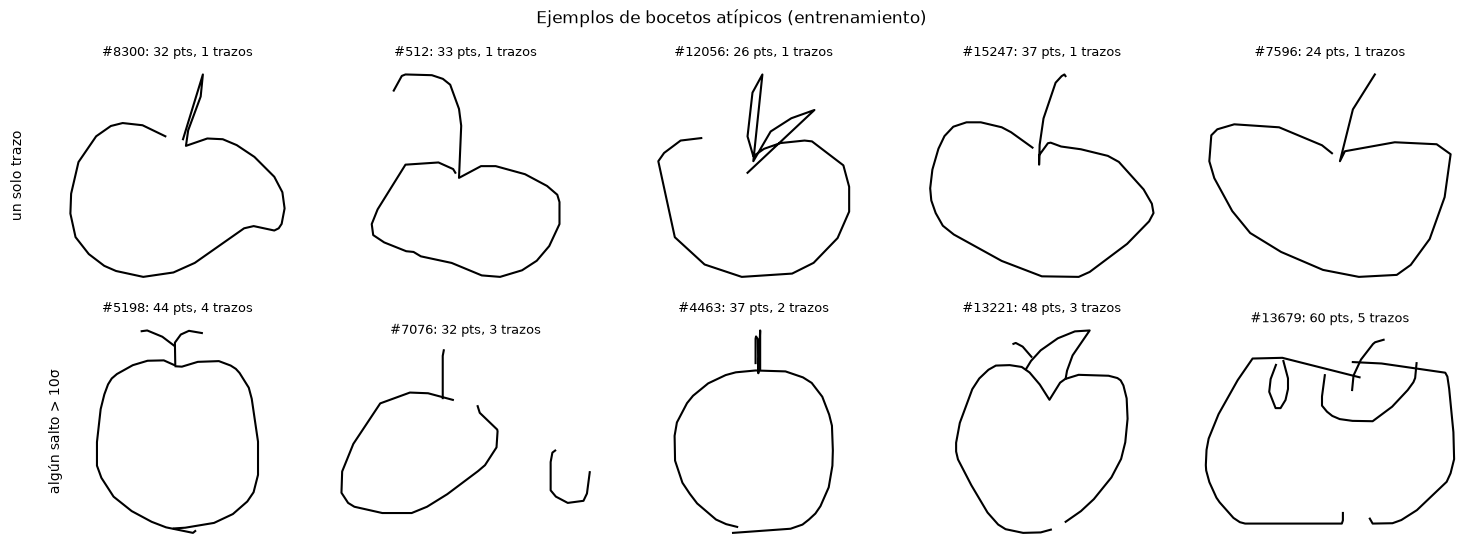

In [10]:
MIN_SKETCH_POINTS = 5
TINY_BOX_FRACTION = 0.10
MAX_JUMP_SIGMAS = 10
MAX_EXAMPLES = 5
OUTLIER_SEED = 1
BBOX_WIDTH_COL = 0
BBOX_HEIGHT_COL = 1


def abs_coords(sketch: np.ndarray) -> np.ndarray:
    """Coordenadas absolutas (x, y) acumulando los desplazamientos de un boceto stroke-3."""
    return np.cumsum(sketch[:, DELTA_XY_SLICE], axis=0)


bbox_wh = np.array([np.ptp(abs_coords(s), axis=0) for s in eda_sk])  # ancho y alto (px)
side = bbox_wh.max(axis=1)
max_jump = np.array([np.max(np.abs(s[:, DELTA_XY_SLICE]) / [sd_x, sd_y]) for s in eda_sk])
median_side = np.median(side)

flags = {
    f"menos de {MIN_SKETCH_POINTS} puntos": lens_eda < MIN_SKETCH_POINTS,
    "un solo trazo": strokes_eda <= 1,
    f"caja < {TINY_BOX_FRACTION * 100:.0f} % de la mediana": side < TINY_BOX_FRACTION * median_side,
    f"algún salto > {MAX_JUMP_SIGMAS}σ": max_jump > MAX_JUMP_SIGMAS,
}
flag_table = pd.DataFrame(
    {
        "bocetos": {k: int(v.sum()) for k, v in flags.items()},
        "%": {k: v.mean() * 100 for k, v in flags.items()},
    }
)
any_flag = np.any(np.stack(list(flags.values())), axis=0)
flag_table.loc["al menos uno"] = [int(any_flag.sum()), any_flag.mean() * 100]
display(
    flag_table.style.format({"bocetos": "{:,.0f}", "%": "{:.2f}"}).set_caption(
        "Bocetos atípicos en entrenamiento"
    )
)

rng_eda = np.random.default_rng(OUTLIER_SEED)
shown = {name: mask for name, mask in flags.items() if mask.any()}  # sólo criterios con casos
fig, axes = plt.subplots(len(shown), MAX_EXAMPLES, figsize=(15, 2.8 * len(shown)), squeeze=False)
for row, (name, mask) in zip(axes, shown.items(), strict=True):
    ids = np.flatnonzero(mask)
    chosen = rng_eda.choice(ids, min(MAX_EXAMPLES, len(ids)), replace=False) if len(ids) else []
    for j, ax in enumerate(row):
        ax.axis("off")
        if j < len(chosen):
            k = chosen[j]
            draw_sketch(ax, eda_sk[k], lw=1.5)
            ax.set_title(f"#{k}: {lens_eda[k]} pts, {int(strokes_eda[k])} trazos", fontsize=9)
    label_axis = row[0]
    label_axis.text(
        -0.15,
        0.5,
        name,
        transform=label_axis.transAxes,
        rotation=90,
        ha="right",
        va="center",
        fontsize=10,
    )
plt.suptitle("Ejemplos de bocetos atípicos (entrenamiento)")
plt.tight_layout()
plt.show()

### b) Duplicados

Un boceto repetido entre entrenamiento y prueba inflaría las métricas de prueba. Se buscan duplicados **exactos** y
**casi idénticos** (mismo número de puntos, mismos estados del lápiz y posiciones absolutas iguales en una cuadrícula
de 8 px).

In [11]:
NEAR_DUPLICATE_GRID_PX = 8


def key_exact(sketch: np.ndarray) -> bytes:
    """Clave de un boceto exacto: sus valores stroke-3 truncados, sin interpretación."""
    return np.asarray(sketch[:EDA_MAX_POINTS], dtype=np.int32).tobytes()


def key_near(sketch: np.ndarray, grid: int = NEAR_DUPLICATE_GRID_PX) -> bytes:
    """Clave de un boceto casi idéntico: posiciones en cuadrícula + estados del lápiz."""
    sketch = np.asarray(sketch[:EDA_MAX_POINTS], dtype=np.float64)
    coords = abs_coords(sketch)
    coords = coords - coords.min(axis=0)
    return (
        np.round(coords / grid).astype(np.int32).tobytes()
        + sketch[:, PEN_LIFT_COL].astype(np.int8).tobytes()
    )


split_sets = {
    "train": raw_train[:N_TRAIN],
    "valid": raw_valid[:N_VALID],
    "test": raw_test[:N_TEST],
}
dup_rows: dict[str, dict[str, int]] = {}
for kind, key_fn in [("exactos", key_exact), ("casi idénticos", key_near)]:
    keys = {name: [key_fn(s) for s in sketches] for name, sketches in split_sets.items()}
    row = {f"dentro de {name}": len(k) - len(set(k)) for name, k in keys.items()}
    for a, b in [("train", "valid"), ("train", "test"), ("valid", "test")]:
        keys_b = set(keys[b])
        row[f"{a} ∩ {b}"] = sum(k in keys_b for k in set(keys[a]))
    dup_rows[kind] = row
display(
    pd.DataFrame(dup_rows).T.style.set_caption("Bocetos duplicados (número de bocetos repetidos)")
)

,dentro de train,dentro de valid,dentro de test,train ∩ valid,train ∩ test,valid ∩ test
exactos,0,0,0,0,0,0
casi idénticos,0,0,0,0,0,0


### c) Comparación entre entrenamiento, validación y prueba

Se comparan las distribuciones de longitud, número de trazos, tamaño medio de los desplazamientos y relación de
aspecto en los tres conjuntos del split obligatorio. El estadístico **D de Kolmogorov–Smirnov** mide la máxima
diferencia entre las distribuciones acumuladas (0 = idénticas); con 2.000 bocetos, valores de D < 0.05 indican
distribuciones prácticamente iguales.

,longitud (puntos),trazos,|Δ| medio (px),aspecto (ancho/alto),D KS longitud,D KS trazos,D KS |Δ|,D KS aspecto
train,37.963,2.731,31.952,0.884,—,—,—,—
valid,38.102,2.683,31.875,0.886,0.013,0.016,0.012,0.028
test,37.913,2.727,31.835,0.882,0.008,0.012,0.024,0.017


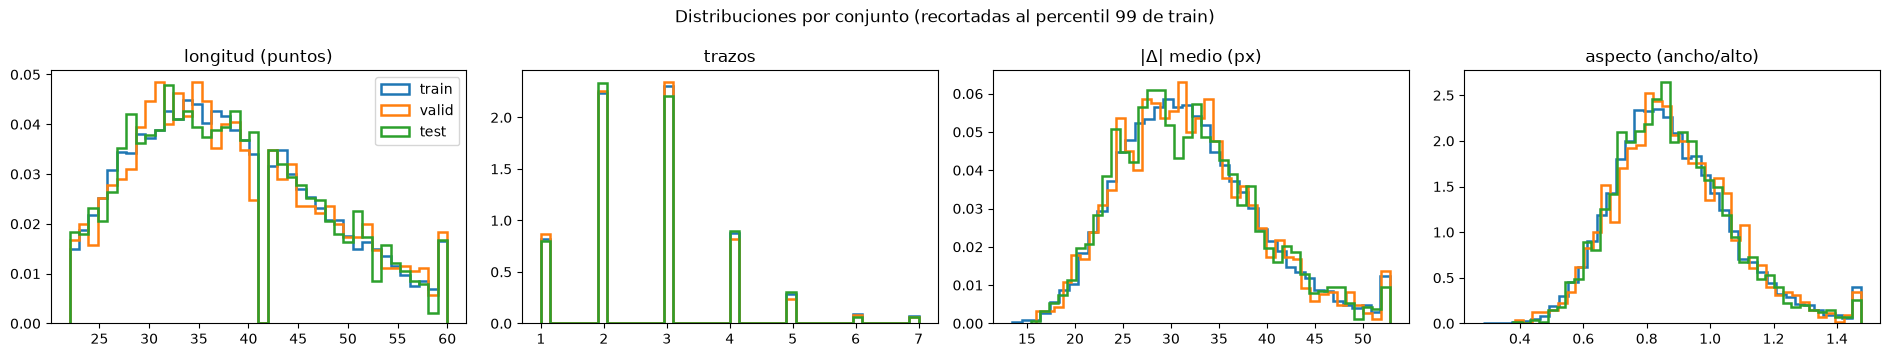

In [12]:
DISPLAY_PERCENTILE = 99


def sketch_features(sketches: Sequence[np.ndarray]) -> pd.DataFrame:
    """Características por boceto para comparar los tres conjuntos del split."""
    truncated = [np.asarray(s[:EDA_MAX_POINTS], dtype=np.float64) for s in sketches]
    wh = np.array([np.ptp(abs_coords(s), axis=0) for s in truncated])
    return pd.DataFrame(
        {
            "longitud (puntos)": [len(s) for s in truncated],
            "trazos": [s[:, PEN_LIFT_COL].sum() for s in truncated],
            "|Δ| medio (px)": [np.hypot(s[:, DX_COL], s[:, DY_COL]).mean() for s in truncated],
            "aspecto (ancho/alto)": wh[:, BBOX_WIDTH_COL] / np.maximum(wh[:, BBOX_HEIGHT_COL], 1),
        }
    )


feats = {name: sketch_features(sk) for name, sk in split_sets.items()}
summary = pd.DataFrame({name: features.mean() for name, features in feats.items()}).T
for column in feats["train"].columns:
    for name in ("valid", "test"):
        ks_statistic = stats.ks_2samp(feats["train"][column], feats[name][column]).statistic
        metric_name = column.split(" ")[0]
        summary.loc[name, f"D KS {metric_name}"] = ks_statistic
display(
    summary.style.format("{:.3f}", na_rep="—").set_caption(
        "Medias por conjunto y estadístico D de KS frente a train"
    )
)

fig, axes = plt.subplots(1, 4, figsize=(19, 3.6))
for ax, column in zip(axes, feats["train"].columns, strict=True):
    hi = np.percentile(feats["train"][column], DISPLAY_PERCENTILE)
    for name, features in feats.items():
        ax.hist(
            np.clip(features[column], None, hi),
            bins=40,
            density=True,
            histtype="step",
            lw=1.8,
            label=name,
        )
    ax.set_title(column)
axes[0].legend()
plt.suptitle("Distribuciones por conjunto (recortadas al percentil 99 de train)")
plt.tight_layout()
plt.show()

## 3.3 Estructura del dibujo

### a) Tamaño y proporción de los bocetos → rango del aumento de datos

El aumento de datos del entrenamiento escala Δx y Δy por factores independientes en [0.85, 1.15], lo que cambia la
relación de aspecto hasta ×1.35. Se compara ese rango con la variación natural del tamaño y de la proporción de los
bocetos.

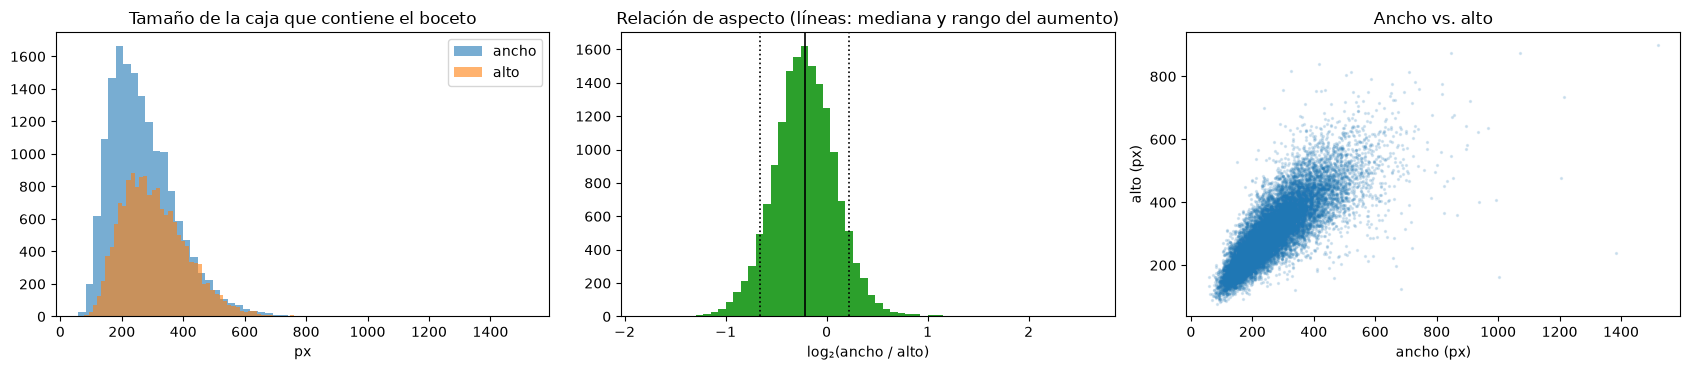

Ancho mediano 251 px | alto mediano 293 px
Aspecto: mediana 0.86, rango intercuartílico [0.75, 0.99] (cociente p75/p25 = 1.32); el aumento de datos lo cambia como máximo ×1.35


In [13]:
AUGMENT_SCALE_MIN = 0.85
AUGMENT_SCALE_MAX = 1.15
QUARTILES = (25, 50, 75)

width, height = bbox_wh[:, BBOX_WIDTH_COL], bbox_wh[:, BBOX_HEIGHT_COL]
aspect = width / np.maximum(height, 1)
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
axes[0].hist(width, bins=60, alpha=0.6, label="ancho")
axes[0].hist(height, bins=60, alpha=0.6, label="alto")
axes[0].set_xlabel("px")
axes[0].set_title("Tamaño de la caja que contiene el boceto")
axes[0].legend()
axes[1].hist(np.log2(aspect), bins=60, color="C2")
aspect_factors = (AUGMENT_SCALE_MIN / AUGMENT_SCALE_MAX, AUGMENT_SCALE_MAX / AUGMENT_SCALE_MIN)
for factor in aspect_factors:
    axes[1].axvline(np.log2(np.median(aspect) * factor), color="k", ls=":", lw=1.2)
axes[1].axvline(np.log2(np.median(aspect)), color="k", lw=1.2)
axes[1].set_xlabel("log₂(ancho / alto)")
axes[1].set_title("Relación de aspecto (líneas: mediana y rango del aumento)")
axes[2].scatter(width, height, s=2, alpha=0.15)
axes[2].set_xlabel("ancho (px)")
axes[2].set_ylabel("alto (px)")
axes[2].set_title("Ancho vs. alto")
plt.tight_layout()
plt.show()
q25, q50, q75 = np.percentile(aspect, QUARTILES)
print(f"Ancho mediano {np.median(width):.0f} px | alto mediano {np.median(height):.0f} px")
print(
    f"Aspecto: mediana {q50:.2f}, rango intercuartílico [{q25:.2f}, {q75:.2f}] "
    f"(cociente p75/p25 = {q75 / q25:.2f}); el aumento de datos lo cambia como máximo "
    f"×{AUGMENT_SCALE_MAX / AUGMENT_SCALE_MIN:.2f}"
)

### b) Puntos por trazo y orden de los trazos

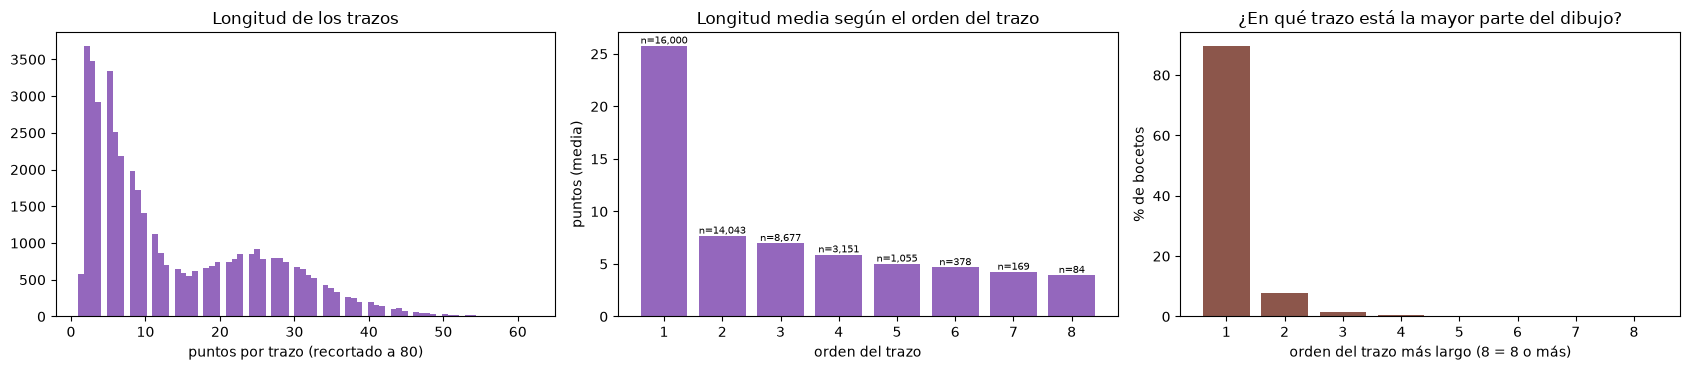

Trazos por boceto: mediana 3 | puntos por trazo: mediana 9
El primer trazo contiene en mediana el 72 % de los puntos del boceto, y es el más largo en el 90 % de los bocetos.


In [14]:
MAX_STROKE_ORDER = 8
MAX_STROKE_LEN_SHOWN = 80
STROKE_LEN_BINS = 80


def split_strokes(sketch: np.ndarray) -> list[np.ndarray]:
    """Divide un boceto stroke-3 en trazos usando las marcas pen_lift = 1."""
    ends = np.where(sketch[:, PEN_LIFT_COL] == PEN_LIFT_END)[0] + 1
    return [stroke for stroke in np.split(sketch, ends) if len(stroke)]


strokes_per_sketch = [split_strokes(s) for s in eda_sk]
stroke_len = np.concatenate([[len(stroke) for stroke in strokes] for strokes in strokes_per_sketch])
order_len = [
    [len(strokes[i]) for strokes in strokes_per_sketch if len(strokes) > i]
    for i in range(MAX_STROKE_ORDER)
]
# +1: el orden del trazo se muestra 1-based.
longest_order = np.array(
    [int(np.argmax([len(stroke) for stroke in strokes])) + 1 for strokes in strokes_per_sketch]
)
first_share = np.array(
    [len(strokes[0]) / sum(len(stroke) for stroke in strokes) for strokes in strokes_per_sketch]
)

fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
axes[0].hist(np.clip(stroke_len, None, MAX_STROKE_LEN_SHOWN), bins=STROKE_LEN_BINS, color="C4")
axes[0].set_xlabel(f"puntos por trazo (recortado a {MAX_STROKE_LEN_SHOWN})")
axes[0].set_title("Longitud de los trazos")
axes[1].bar(range(1, MAX_STROKE_ORDER + 1), [np.mean(lengths) for lengths in order_len], color="C4")
for i, lengths in enumerate(order_len):
    axes[1].text(
        i + 1, np.mean(lengths), f"n={len(lengths):,}", ha="center", va="bottom", fontsize=7
    )
axes[1].set_xlabel("orden del trazo")
axes[1].set_ylabel("puntos (media)")
axes[1].set_title("Longitud media según el orden del trazo")
orders, counts = np.unique(np.clip(longest_order, 1, MAX_STROKE_ORDER), return_counts=True)
axes[2].bar(orders, counts / len(longest_order) * 100, color="C5")
axes[2].set_xlabel(f"orden del trazo más largo ({MAX_STROKE_ORDER} = {MAX_STROKE_ORDER} o más)")
axes[2].set_ylabel("% de bocetos")
axes[2].set_title("¿En qué trazo está la mayor parte del dibujo?")
plt.tight_layout()
plt.show()
print(
    f"Trazos por boceto: mediana {np.median([len(s) for s in strokes_per_sketch]):.0f} | "
    f"puntos por trazo: mediana {np.median(stroke_len):.0f}"
)
print(
    f"El primer trazo contiene en mediana el {np.median(first_share) * 100:.0f} % de los puntos del boceto, "
    f"y es el más largo en el {(longest_order == 1).mean() * 100:.0f} % de los bocetos."
)

### c) Mapa de calor de la tinta y punto de inicio

Cada boceto se centra en su caja y se escala para que su lado mayor mida 1. Luego se muestrean puntos a lo largo de
los trazos dibujados, para que los tramos rectos (con pocos puntos tras la simplificación RDP) pesen igual que las
curvas. El mapa resume la **forma típica** de la categoría y dónde suele **empezar** el dibujo.

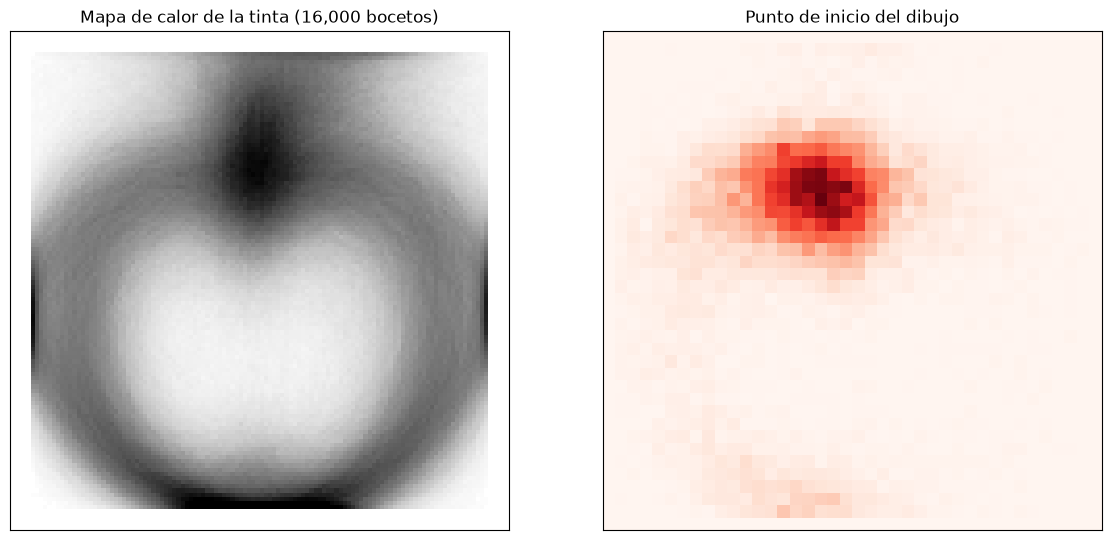

In [15]:
MIN_BOX_SCALE = 1e-6
INK_SAMPLE_STEP = 0.01
INK_RANGE = 0.55
INK_BINS = 120
START_BINS = 40
INK_PERCENTILE = 99.5
INK_EXTENT = [-INK_RANGE, INK_RANGE, -INK_RANGE, INK_RANGE]
INK_X_RANGE = INK_EXTENT[:2]
INK_Y_RANGE = INK_EXTENT[2:]


def normalized_ink(
    sketch: np.ndarray,
    step: float = INK_SAMPLE_STEP,
) -> tuple[np.ndarray, np.ndarray]:
    """Puntos equiespaciados sobre los trazos de un boceto normalizado a su caja (lado mayor = 1)."""
    coords = abs_coords(sketch)
    center = (coords.max(axis=0) + coords.min(axis=0)) / 2
    scale = max(np.ptp(coords, axis=0).max(), MIN_BOX_SCALE)
    coords = (coords - center) / scale
    sampled: list[np.ndarray] = []
    stroke_ends = np.where(sketch[:, PEN_LIFT_COL] == PEN_LIFT_END)[0] + 1
    for idx in np.split(np.arange(len(sketch)), stroke_ends):
        if len(idx) < 2:
            continue
        points = coords[idx]
        arc = np.r_[0, np.cumsum(np.hypot(*np.diff(points, axis=0).T))]
        t = np.arange(0, arc[-1] + step, step)
        sampled.append(
            np.c_[np.interp(t, arc, points[:, DX_COL]), np.interp(t, arc, points[:, DY_COL])]
        )
    ink = np.vstack(sampled) if sampled else np.empty((0, N_DELTA_DIMENSIONS))
    return ink, coords[0]


ink, starts = zip(*(normalized_ink(s) for s in eda_sk), strict=True)
ink, starts = np.vstack(ink), np.array(starts)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
hist, _, _ = np.histogram2d(
    -ink[:, DY_COL],
    ink[:, DX_COL],
    bins=INK_BINS,
    range=[INK_X_RANGE, INK_Y_RANGE],
)
hist = np.sqrt(hist)  # raíz cuadrada para ver zonas de poca y mucha tinta
axes[0].imshow(
    hist,
    origin="lower",
    extent=INK_EXTENT,
    cmap="Greys",
    vmax=np.percentile(hist, INK_PERCENTILE),
)
axes[0].set_title(f"Mapa de calor de la tinta ({N_TRAIN:,} bocetos)")
axes[1].hist2d(
    starts[:, DX_COL],
    -starts[:, DY_COL],
    bins=START_BINS,
    range=[INK_X_RANGE, INK_Y_RANGE],
    cmap="Reds",
)
axes[1].set_title("Punto de inicio del dibujo")
for ax in axes:
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

### d) Orden y sentido de dibujo

Se analiza el primer trazo: la **dirección del primer movimiento** y, cuando el trazo es aproximadamente cerrado
(sus extremos quedan a menos del 20 % del tamaño del boceto), si se recorre en **sentido horario o antihorario**. Son
hábitos de dibujo que el modelo debe aprender además de la forma.

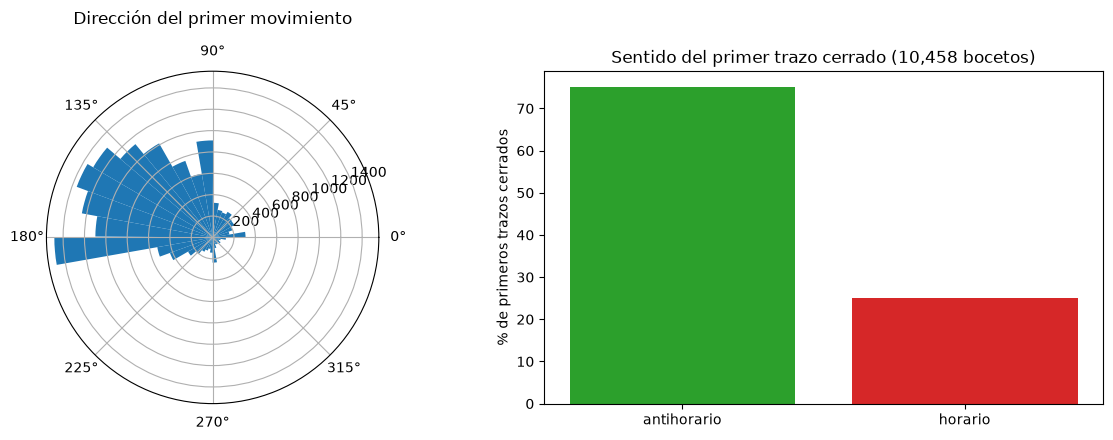

Primer movimiento: {'izquierda': 51.3, 'arriba': 32.7, 'derecha': 9.0, 'abajo': 7.0}
Primeros trazos cerrados: 65 % de los bocetos | antihorario: 75 %, horario: 25 %


In [16]:
MIN_POINTS_FOR_ORIENTATION = 5
CLOSED_STROKE_TOLERANCE = 0.20
DIRECTION_EDGES_DEG = (-180, -135, -45, 45, 135, 180)
DIRECTION_INNER_EDGES_DEG = DIRECTION_EDGES_DEG[1:-1]
DIRECTION_LABELS = ("izquierda", "abajo", "derecha", "arriba", "izquierda")

first_dir, orient = [], []
for sketch, strokes in zip(eda_sk, strokes_per_sketch, strict=True):
    first = strokes[0]
    first_dir.append(
        np.arctan2(-first[0, DY_COL], first[0, DX_COL])
    )  # primer movimiento (y arriba)
    if len(first) >= MIN_POINTS_FOR_ORIENTATION:
        coords = np.cumsum(first[:, DELTA_XY_SLICE], axis=0) * [1, -1]  # coordenadas con y arriba
        size = max(np.ptp(abs_coords(sketch), axis=0).max(), MIN_BOX_SCALE)
        start_point, end_point = coords[0], coords[-1]
        if np.hypot(*(end_point - start_point)) < CLOSED_STROKE_TOLERANCE * size:
            x, y = coords[:, DX_COL], coords[:, DY_COL]
            area = 0.5 * np.sum(
                x * np.roll(y, -1) - np.roll(x, -1) * y
            )  # área con signo (shoelace)
            orient.append("antihorario" if area > 0 else "horario")
first_dir = np.array(first_dir)
orient = pd.Series(orient)

fig = plt.figure(figsize=(12, 4.5))
ax = fig.add_subplot(1, 2, 1, projection="polar")
ax.hist(first_dir, bins=36, color="C0")
ax.set_title("Dirección del primer movimiento", pad=15)
ax = fig.add_subplot(1, 2, 2)
orientation_counts = orient.value_counts()
ax.bar(
    orientation_counts.index,
    orientation_counts.to_numpy() / orientation_counts.sum() * 100,
    color=["C2", "C3"][: len(orientation_counts)],
)
ax.set_ylabel("% de primeros trazos cerrados")
ax.set_title(f"Sentido del primer trazo cerrado ({len(orient):,} bocetos)")
plt.tight_layout()
plt.show()

# right=True: el límite superior pertenece al intervalo, igual que en pd.cut.
quadrant_idx = np.digitize(np.degrees(first_dir), DIRECTION_INNER_EDGES_DEG, right=True)
quadrant = pd.Series([DIRECTION_LABELS[i] for i in quadrant_idx])
print("Primer movimiento:", (quadrant.value_counts(normalize=True) * 100).round(1).to_dict())
print(
    f"Primeros trazos cerrados: {len(orient) / N_TRAIN * 100:.0f} % de los bocetos | "
    + ", ".join(
        f"{k}: {v / orientation_counts.sum() * 100:.0f} %" for k, v in orientation_counts.items()
    )
)

### Hallazgos de la exploración (`apple`)

**Diseño del modelo (3.1)**
- **Dos regímenes de movimiento → MDN.** Dentro de un trazo, la varianza de Δ normalizado es 0.75. En el primer punto
  tras levantar el lápiz es **6.2 (8 veces mayor)**: esos saltos son sólo el 4.7 % de los puntos, pero aportan el
  **28.7 %** del error cuadrático de una predicción constante. Una única gaussiana, o la media que aprende una
  regresión MSE, no describe ambos regímenes. Una mezcla de gaussianas sí.
- **Colas pesadas → normalización.** La curtosis en exceso es 31.7 (Δx) y 21.7 (Δy), frente a 0 en una normal, y hay
  desplazamientos de hasta 1.322 px (48σ). Normalizar por la desviación estándar deja la mayoría de los valores en
  ±1–2. Sólo 1 boceto tiene un salto mayor de 1.000 px, por lo que no hace falta recortar.
- **Memoria → LSTM.** Hay una autocorrelación fuerte entre puntos consecutivos (Δx: +0.51; Δy: +0.38), y la de Δx se
  vuelve **negativa (≈ −0.3) hacia k ≈ 10**: tras recorrer medio contorno, el lápiz va en la dirección opuesta. Es la
  huella del contorno circular, y el modelo sólo la captura si recuerda varios pasos atrás.
- **`pen_state` → pesos por clase.** Levantar el lápiz es casi imposible en la primera mitad del boceto
  (P = 0.008 en el primer 10 %) y muy probable al final (0.26 en el último 10 %), porque primero se dibuja el contorno
  y luego el tallo y la hoja. La tasa de fin es 0 hasta t ≈ 21 y sube hasta 0.36 en t = 60. Con sólo 2.6 % de puntos
  "fin" y 7.0 % "levanta", los pesos 4.54 y 2.75 compensan el desbalance.

**Calidad de los datos (3.2)**
- No hay bocetos con menos de 5 puntos ni demasiado pequeños. Los 1.957 bocetos de **un solo trazo** (12.2 %) y los 329
  con saltos de más de 10σ son **dibujos legítimos**: manzanas completas sin levantar el lápiz, o saltos para dibujar
  el tallo o la hoja. No hay datos basura que filtrar.
- **Sin duplicados**, ni exactos ni casi idénticos, dentro de cada conjunto ni entre ellos: las métricas de prueba no
  están infladas por bocetos repetidos.
- Train, validación y prueba tienen distribuciones prácticamente iguales (D de KS ≤ 0.03 en las cuatro variables): la
  prueba es representativa.

**Estructura del dibujo (3.3)**
- Las manzanas son algo más altas que anchas (aspecto mediano 0.86). La variación natural del aspecto (cociente
  intercuartílico 1.32) es comparable a lo que cambia el aumento de datos (hasta ×1.35): el rango [0.85, 1.15] genera
  variaciones realistas.
- El **primer trazo es el contorno**: contiene en mediana el 72 % de los puntos y es el más largo en el 90 % de los
  bocetos. Los trazos siguientes (tallo y hoja) son cortos (5–8 puntos).
- El dibujo típico **empieza arriba al centro** (la hendidura donde nace el tallo), sale **hacia la izquierda**
  (51 % de los primeros movimientos) y recorre el contorno en **sentido antihorario** (75 % de los primeros trazos
  cerrados). Es un hábito de dibujo muy consistente, que el modelo deberá aprender.

# 4. Preprocesamiento

Pasos (todas las estadísticas se calculan **sólo con los 16.000 bocetos de entrenamiento**, para no filtrar
información de validación/prueba):

1. **Normalización:** Δx y Δy se dividen por su desviación estándar (σx, σy). Se revierte al generar.
2. **Conversión stroke-3 → stroke-5:** `p1 = 1 − pen_lift` (el lápiz sigue en el papel), `p2 = pen_lift`
   (se levanta tras el punto), `p3` = fin del dibujo. Se añade explícitamente un punto final `(0, 0, 0, 0, 1)`.
3. **Truncado y relleno a 200 puntos:** cada boceto conserva a lo sumo 199 puntos reales + el punto de fin
   (≤ 200 en total). Si se trunca, el último punto conservado cierra el trazo (`p2 = 1`). Las posiciones restantes
   se rellenan con `(0, 0, 0, 0, 1)`.
4. **Máscara:** se guarda la longitud real (puntos + punto de fin) de cada secuencia; con ella se construye la
   máscara que excluye el relleno de la pérdida y de las métricas.
5. **Pares entrada → objetivo:** entrada = `[S0, s_1, …, s_199]`, objetivo = `[s_1, …, s_200]`. Para el objetivo
   de `pen_state` se usa el índice de clase (0, 1, 2).

In [17]:
# Desviación estándar de Δx y Δy calculada SOLO con los N_TRAIN bocetos de entrenamiento
train_pts = np.concatenate([s[: MAX_LEN - 1] for s in raw_train[:N_TRAIN]]).astype(np.float64)
STD_X, STD_Y = train_pts[:, DX_COL].std(), train_pts[:, DY_COL].std()
print(f"σx = {STD_X:.3f} | σy = {STD_Y:.3f}")

# Formato stroke-5: (Δx/σx, Δy/σy, p1 dibuja, p2 levanta, p3 fin)
STROKE5_SIZE = 5
S5_DX_COL = 0
S5_DY_COL = 1
S5_DRAW_COL = 2
S5_LIFT_COL = 3
S5_END_COL = 4
S5_XY_SLICE = slice(S5_DX_COL, S5_DY_COL + 1)
PEN_STATE_SLICE = slice(S5_DRAW_COL, S5_END_COL + 1)
PEN_LIFT_PAIR_SLICE = slice(S5_DRAW_COL, S5_LIFT_COL + 1)
LAST_DIM = -1
TIME_AXIS = 1
START_TOKEN = np.zeros(STROKE5_SIZE, dtype=np.float32)
START_TOKEN[S5_DRAW_COL] = 1.0  # S0 = (0, 0, 1, 0, 0)


def to_stroke5(s3: np.ndarray, max_len: int = MAX_LEN) -> tuple[np.ndarray, int]:
    """stroke-3 (N, 3) -> stroke-5 (max_len, 5) normalizado + longitud real (incluye el punto de fin)."""
    if max_len <= 1:
        raise ValueError("max_len debe reservar al menos una posición para el punto de fin")
    s3 = np.asarray(s3[: max_len - 1], dtype=np.float32)  # deja espacio para el punto de fin
    n = len(s3)
    if n == 0:
        raise ValueError("el boceto no tiene puntos")
    s5 = np.zeros((max_len, STROKE5_SIZE), dtype=np.float32)
    s5[:n, S5_DX_COL] = s3[:, DX_COL] / STD_X
    s5[:n, S5_DY_COL] = s3[:, DY_COL] / STD_Y
    s5[:n, S5_DRAW_COL] = 1 - s3[:, PEN_LIFT_COL]  # p1: el lápiz sigue tocando el papel
    s5[:n, S5_LIFT_COL] = s3[:, PEN_LIFT_COL]  # p2: el lápiz se levanta después de este punto
    s5[n - 1, PEN_LIFT_PAIR_SLICE] = (0, 1)  # el último punto real cierra su trazo (si se truncó)
    s5[n:, S5_END_COL] = 1  # p3: fin del dibujo en n y relleno después
    return s5, n + 1


def build_tensors(
    sketches: Sequence[np.ndarray],
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor]:
    """Construye los tensores de entrada, objetivo y longitudes de un conjunto de bocetos."""
    s5, lens = zip(*(to_stroke5(s) for s in sketches), strict=True)
    s5 = np.stack(s5)  # (N, 200, 5)
    assert s5.shape[1:] == (MAX_LEN, STROKE5_SIZE)
    start = np.broadcast_to(START_TOKEN, (len(s5), 1, STROKE5_SIZE)).copy()  # S0 por secuencia
    x = np.concatenate([start, s5[:, :-1]], axis=TIME_AXIS)  # entrada: S0, s_1, ..., s_199
    y = s5  # objetivo: s_1, ..., s_200
    return torch.from_numpy(x), torch.from_numpy(y), torch.tensor(lens, dtype=torch.long)


def length_mask(lens: torch.Tensor, max_len: int = MAX_LEN) -> torch.Tensor:
    """Máscara booleana (B, max_len): True en los puntos reales, False en el relleno."""
    return torch.arange(max_len, device=lens.device)[None, :] < lens[:, None]


# Verificación con un ejemplo
s5_demo, n_demo = to_stroke5(raw_train[0])
print("Longitud real (con punto de fin):", n_demo)
print("Primeros puntos stroke-5:\n", np.round(s5_demo[:4], 3))
print("Puntos alrededor del final:\n", np.round(s5_demo[n_demo - 2 : n_demo + 2], 3))

σx = 27.686 | σy = 32.515
Longitud real (con punto de fin): 44
Primeros puntos stroke-5:
 [[-0.614 -0.554  1.     0.     0.   ]
 [-0.686 -0.431  1.     0.     0.   ]
 [-1.156 -0.062  1.     0.     0.   ]
 [-0.47   0.154  1.     0.     0.   ]]
Puntos alrededor del final:
 [[-0.65  -0.246  0.     1.     0.   ]
 [ 0.     0.     0.     0.     1.   ]
 [ 0.     0.     0.     0.     1.   ]
 [ 0.     0.     0.     0.     1.   ]]


# 5. Split train / validación / prueba

Se aplica el split obligatorio **16.000 / 2.000 / 2.000** (80 / 10 / 10, 20.000 bocetos en total) tomando los
primeros bocetos de cada conjunto provisto en el `.npz` (`train`, `valid`, `test`), de modo que no hay mezcla entre
conjuntos. Validación se usa para *early stopping* y para monitorear el entrenamiento; prueba sólo al final.

La unidad independiente es el **boceto**: no hay agrupamientos (autor, paciente, año) que obliguen a un split
agrupado. El enunciado fija el split, por lo que no se aplica validación cruzada: validación cumple el papel de
conjunto de selección y prueba se toca una única vez, al final.

In [18]:
sk_train, sk_valid, sk_test = raw_train[:N_TRAIN], raw_valid[:N_VALID], raw_test[:N_TEST]
# El enunciado fija el split 16.000 / 2.000 / 2.000; por eso no se usa validación cruzada:
# validación cumple el papel de selección y prueba se toca una sola vez.
assert len(sk_train) + len(sk_valid) + len(sk_test) <= N_TRAIN + N_VALID + N_TEST

X_train, Y_train, L_train = build_tensors(sk_train)
X_valid, Y_valid, L_valid = build_tensors(sk_valid)
X_test, Y_test, L_test = build_tensors(sk_test)

for name, X, L, sketches in [
    ("train", X_train, L_train, sk_train),
    ("valid", X_valid, L_valid, sk_valid),
    ("test", X_test, L_test, sk_test),
]:
    n_truncated = sum(len(s) > MAX_LEN - 1 for s in sketches)
    print(
        f"{name:5s} -> X {tuple(X.shape)} | puntos reales: {int(L.sum()):,} | "
        f"bocetos truncados: {n_truncated}"
    )
assert int(L_train.max()) <= MAX_LEN

# Distribución de pen_state en los puntos reales del objetivo de entrenamiento
mask_train = length_mask(L_train)
pen_train = Y_train[..., PEN_STATE_SLICE].argmax(LAST_DIM)[mask_train]
class_counts = torch.bincount(pen_train, minlength=NUM_PEN_STATES).float()
class_freq = class_counts / class_counts.sum()
print("Frecuencia pen_state (dibuja, levanta, fin):", np.round(class_freq.numpy(), 4))

BATCH_SIZE = 128
EVAL_BATCH_SIZE = 256
train_loader = DataLoader(
    TensorDataset(X_train, Y_train, L_train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    drop_last=True,
    generator=torch.Generator().manual_seed(SEED),
)
valid_loader = DataLoader(TensorDataset(X_valid, Y_valid, L_valid), batch_size=EVAL_BATCH_SIZE)
test_loader = DataLoader(TensorDataset(X_test, Y_test, L_test), batch_size=EVAL_BATCH_SIZE)

train -> X (16000, 200, 5) | puntos reales: 623,404 | bocetos truncados: 0
valid -> X (2000, 200, 5) | puntos reales: 78,203 | bocetos truncados: 0
test  -> X (2000, 200, 5) | puntos reales: 77,825 | bocetos truncados: 0
Frecuencia pen_state (dibuja, levanta, fin): [0.9043 0.0701 0.0257]


# 6. Arquitectura y creación del modelo

El modelo es una red recurrente en PyTorch (`SketchRNN`) que sigue el diagrama de la portada. Recibe los puntos del boceto en formato stroke-5 y los pasa por una LSTM de 2 capas de 512 unidades (dropout 0.2 entre capas) y por otro dropout. De ahí salen dos cabezas:

- una **cabeza MDN**, `Linear(512 → 6·M)` con M = 20, que describe una mezcla de gaussianas para el siguiente (Δx, Δy): π con softmax (los pesos suman 1), σx y σy con exponencial (siempre positivas) y ρ con tanh (entre −1 y 1);
- una **cabeza de `pen_state`**, `Linear(512 → 3)`, que da los logits de las tres clases (dibuja, levanta, fin).

La celda sólo crea el modelo y comprueba que las dimensiones de las salidas sean las esperadas; no entrena nada. También define la función que genera un boceto punto a punto, que se usa en la sección 9.

In [19]:
# Arquitectura del modelo (coherente con el diagrama de la portada):
#   LSTM 2 capas x 512 (dropout 0.2) -> dropout -> cabeza MDN Linear(512 -> 6*M) con M = 20
#   y cabeza Linear(512 -> 3) para pen_state.
# Esta celda SOLO crea la arquitectura (pesos inicializados) y verifica dimensiones; no entrena.

NUM_MIXTURES = 20  # M: componentes de la mezcla de gaussianas
MDN_PARAMS_PER_MIXTURE = 6  # pi, mu_x, mu_y, sigma_x, sigma_y, rho
HIDDEN_SIZE = 512
NUM_LSTM_LAYERS = 2
DROPOUT = 0.2
LOG_SIGMA_MIN = -7.0
LOG_SIGMA_MAX = 3.0
SINGLE_BATCH_INDEX = 0
FIRST_TIME_STEP = 0
LAST_TIME_STEP = -1
DEMO_BATCH_SIZE = 4


class MDNParams(NamedTuple):
    """Parámetros de la mezcla de gaussianas bivariadas en cada paso."""

    pi: torch.Tensor
    mu_x: torch.Tensor
    mu_y: torch.Tensor
    sigma_x: torch.Tensor
    sigma_y: torch.Tensor
    rho: torch.Tensor


LSTMState = tuple[torch.Tensor, torch.Tensor]


class SketchRNN(nn.Module):
    def __init__(
        self,
        input_size: int = STROKE5_SIZE,
        hidden_size: int = HIDDEN_SIZE,
        num_layers: int = NUM_LSTM_LAYERS,
        num_mixtures: int = NUM_MIXTURES,
        dropout: float = DROPOUT,
    ) -> None:
        super().__init__()
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.num_mixtures = num_mixtures

        # Codificador recurrente: LSTM de 2 capas x 512, dropout 0.2 entre capas
        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout,
        )
        self.drop = nn.Dropout(dropout)

        # Cabeza MDN: Linear(512 -> 6*M) -> (pi, mu_x, mu_y, sigma_x, sigma_y, rho)
        self.mdn = nn.Linear(hidden_size, MDN_PARAMS_PER_MIXTURE * num_mixtures)
        # Cabeza de clasificación de pen_state: Linear(512 -> 3)
        self.pen = nn.Linear(hidden_size, NUM_PEN_STATES)

    def forward(
        self,
        x: torch.Tensor,
        state: LSTMState | None = None,
    ) -> tuple[MDNParams, torch.Tensor, LSTMState]:
        """x: (B, T, 5). Devuelve (parámetros de la mezcla, logits de pen_state, state)."""
        h, state = self.lstm(x, state)  # (B, T, 512)
        h = self.drop(h)

        mdn = self.mdn(h)  # (B, T, 6*M)
        pi, mu_x, mu_y, sigma_x, sigma_y, rho = torch.split(mdn, self.num_mixtures, dim=LAST_DIM)
        pi = F.softmax(pi, dim=LAST_DIM)  # pesos de la mezcla (suman 1)
        sigma_x = torch.exp(sigma_x.clamp(LOG_SIGMA_MIN, LOG_SIGMA_MAX))  # positivas
        sigma_y = torch.exp(sigma_y.clamp(LOG_SIGMA_MIN, LOG_SIGMA_MAX))
        rho = torch.tanh(rho)  # correlación en (-1, 1)

        pen_logits = self.pen(h)  # (B, T, 3)
        params = MDNParams(pi, mu_x, mu_y, sigma_x, sigma_y, rho)
        return params, pen_logits, state


@torch.no_grad()
def generate_sketch(
    model: SketchRNN,
    max_len: int = MAX_LEN,
    temperature: float = 0.5,
    device: torch.device = device,
    delta_mode: str = "mean",
    debias: bool = True,
    class_weights: torch.Tensor | None = None,
) -> np.ndarray:
    """Genera un boceto autorregresivamente desde S0 = (0,0,1,0,0).

    Para (Δx, Δy) usa por defecto la media de la mezcla E[Δ] = Σ πk μk, que es la
    predicción puntual que minimiza el MSE; con delta_mode="sample" muestrea una
    componente y su gaussiana. Para pen_state muestrea softmax(logits/T); con
    debias=True divide las probabilidades por los pesos de clase y renormaliza,
    porque los pesos de la CE sesgan la generación hacia 'fin'. Devuelve un array
    stroke-5 normalizado (T, 5).
    """
    if temperature <= 0:
        raise ValueError("temperature debe ser positiva")
    if delta_mode not in {"mean", "sample"}:
        raise ValueError("delta_mode debe ser 'mean' o 'sample'")
    if debias and class_weights is None:
        raise ValueError("debias=True requiere class_weights")
    was_training = model.training
    model.eval()
    try:
        # (batch, tiempo, features) = (1, 1, 5): se genera un punto por paso.
        x = torch.from_numpy(START_TOKEN).view(1, 1, STROKE5_SIZE).to(device)
        state: LSTMState | None = None
        samples: list[np.ndarray] = []
        for _ in range(max_len):
            params, pen_logits, state = model(x, state)
            pi = params.pi[SINGLE_BATCH_INDEX, LAST_TIME_STEP]
            mu_x = params.mu_x[SINGLE_BATCH_INDEX, LAST_TIME_STEP]
            mu_y = params.mu_y[SINGLE_BATCH_INDEX, LAST_TIME_STEP]

            if delta_mode == "mean":
                # Predicción puntual: media de la mezcla. Es la salida que minimiza
                # el MSE y produce trazos mucho más limpios que muestrear componentes.
                dxdy = torch.stack([(pi * mu_x).sum(), (pi * mu_y).sum()])
            else:
                sigma_x = params.sigma_x[SINGLE_BATCH_INDEX, LAST_TIME_STEP]
                sigma_y = params.sigma_y[SINGLE_BATCH_INDEX, LAST_TIME_STEP]
                rho = params.rho[SINGLE_BATCH_INDEX, LAST_TIME_STEP]
                mixture = int(torch.multinomial(pi, 1).item())
                mean = torch.stack([mu_x[mixture], mu_y[mixture]])
                sx = sigma_x[mixture] * temperature**0.5
                sy = sigma_y[mixture] * temperature**0.5
                cov = torch.stack(
                    [
                        torch.stack([sx * sx, rho[mixture] * sx * sy]),
                        torch.stack([rho[mixture] * sx * sy, sy * sy]),
                    ]
                )
                dxdy = torch.distributions.MultivariateNormal(mean, cov).sample()

            pen_prob = F.softmax(
                pen_logits[SINGLE_BATCH_INDEX, LAST_TIME_STEP] / temperature,
                dim=LAST_DIM,
            )
            if debias:
                assert class_weights is not None
                pen_prob = pen_prob / class_weights
                pen_prob = pen_prob / pen_prob.sum()
            pen_state = int(torch.multinomial(pen_prob, 1).item())

            onehot = F.one_hot(
                torch.tensor(pen_state, device=device), num_classes=NUM_PEN_STATES
            ).float()
            point = torch.cat([dxdy, onehot])
            samples.append(point.cpu().numpy())

            if pen_state == PEN_END_CLASS:  # estado 'fin'
                break
            x = point.view(1, 1, STROKE5_SIZE)  # (batch, tiempo, features) = (1, 1, 5)
        return np.stack(samples)
    finally:
        model.train(was_training)


# Crear la arquitectura y verificar dimensiones con un lote
model = SketchRNN().to(device)
print(model)
n_params = sum(p.numel() for p in model.parameters())
print(f"Parámetros entrenables: {n_params:,}")

model.eval()  # evita que dropout consuma aleatoriedad antes del entrenamiento
with torch.no_grad():
    (pi, mu_x, mu_y, sigma_x, sigma_y, rho), pen_logits, _ = model(
        X_train[:DEMO_BATCH_SIZE].to(device)
    )
model.train()
print(
    "Formas de salida -> pi:",
    tuple(pi.shape),
    "| mu_x:",
    tuple(mu_x.shape),
    "| pen_logits:",
    tuple(pen_logits.shape),
)
print("Suma de pi (debe ser ~1):", float(pi[SINGLE_BATCH_INDEX, FIRST_TIME_STEP].sum()))

SketchRNN(
  (lstm): LSTM(5, 512, num_layers=2, batch_first=True, dropout=0.2)
  (drop): Dropout(p=0.2, inplace=False)
  (mdn): Linear(in_features=512, out_features=120, bias=True)
  (pen): Linear(in_features=512, out_features=3, bias=True)
)
Parámetros entrenables: 3,227,259
Formas de salida -> pi: (4, 200, 20) | mu_x: (4, 200, 20) | pen_logits: (4, 200, 3)
Suma de pi (debe ser ~1): 0.9999998807907104


# 7. Entrenamiento del modelo

El modelo se entrena para acertar en dos cosas a la vez, y la pérdida es la suma de ambas:

- **Movimiento (Δx, Δy):** log-verosimilitud negativa (NLL) de la mezcla de gaussianas. Es baja cuando el modelo le daba alta probabilidad al movimiento real.
- **Estado del lápiz (`pen_state`):** entropía cruzada con pesos por clase (inversos a la raíz de la frecuencia), para que "levanta" y "fin", que son raras, no se pierdan.

Las dos se promedian sólo sobre los puntos reales con `length_mask`, así el relleno no cuenta.

El bucle usa AdamW y, para evitar el sobreajuste, aumento de datos (escalado aleatorio de Δx y Δy entre 0.85 y 1.15), recorte de gradientes, reducción de la tasa de aprendizaje cuando la validación se estanca y *early stopping* con paciencia de 8 épocas. En cada época se evalúa en validación y se guarda el mejor modelo; al final se dibujan las curvas de entrenamiento y validación. Los hiperparámetros se fijaron con valores estándar y se vigilaron en validación. Se reporta una sola corrida (semilla 42).

Configuración: {'seed': 42, 'batch_size': 128, 'eval_batch_size': 256, 'max_epochs': 60, 'patience': 8, 'lr': 0.001, 'weight_decay': 1e-05, 'lr_factor': 0.5, 'lr_patience': 2, 'grad_clip': 5.0, 'pen_loss_weight': 1.0, 'augment_min': 0.85, 'augment_max': 1.15, 'hidden_size': 512, 'num_layers': 2, 'num_mixtures': 20, 'dropout': 0.2, 'generation_temperature': 0.5, 'n_generations': 6}
Pesos de clase: [0.7643 2.7456 4.5368]
ep   1  train 2.4068 (nll 1.7647 ce 0.6422)  valid 1.3843 (nll 0.9738 ce 0.4106)  mse 1.0472  f1 0.6049  lr 1.0e-03  <- mejor
ep   2  train 1.3008 (nll 0.8971 ce 0.4037)  valid 1.0660 (nll 0.6891 ce 0.3770)  mse 0.8190  f1 0.6592  lr 1.0e-03  <- mejor
ep   3  train 1.0890 (nll 0.7113 ce 0.3777)  valid 0.9450 (nll 0.5834 ce 0.3616)  mse 0.7862  f1 0.6702  lr 1.0e-03  <- mejor
ep   4  train 1.0573 (nll 0.6861 ce 0.3712)  valid 0.9004 (nll 0.5475 ce 0.3529)  mse 0.7726  f1 0.6774  lr 1.0e-03  <- mejor
ep   5  train 0.9614 (nll 0.5976 ce 0.3638)  valid 0.8394 (nll 0.4932 ce 

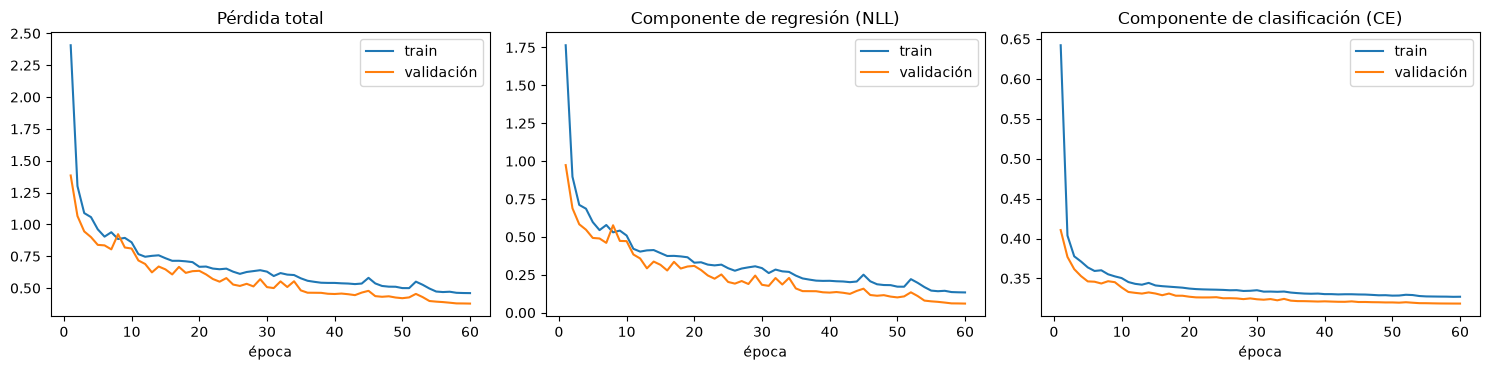

In [20]:
# ---------------------------------------------------------------------------
# Pérdida compuesta enmascarada y bucle de entrenamiento
# ---------------------------------------------------------------------------
MIN_PI = 1e-12
MIN_ONE_MINUS_RHO2 = 1e-6
LOG_2PI = math.log(2.0 * math.pi)
CLASS_NAMES = ("dibuja", "levanta", "fin")


@dataclass(frozen=True)
class TrainConfig:
    """Hiperparámetros fijados con criterios estándar y monitoreados en validación."""

    seed: int = SEED
    batch_size: int = BATCH_SIZE
    eval_batch_size: int = EVAL_BATCH_SIZE
    max_epochs: int = 60
    patience: int = 8
    lr: float = 1e-3
    weight_decay: float = 1e-5
    lr_factor: float = 0.5
    lr_patience: int = 2
    grad_clip: float = 5.0
    pen_loss_weight: float = 1.0
    augment_min: float = 0.85
    augment_max: float = 1.15
    hidden_size: int = HIDDEN_SIZE
    num_layers: int = NUM_LSTM_LAYERS
    num_mixtures: int = NUM_MIXTURES
    dropout: float = DROPOUT
    generation_temperature: float = 0.5
    n_generations: int = 6


@dataclass
class EpochStats:
    loss: float
    reg_loss: float
    pen_loss: float
    mse_x: float
    mse_y: float
    f1_macro: float
    n_points: int


TRAIN_CONFIG = TrainConfig()
CLASS_WEIGHTS = torch.tensor(
    inverse_sqrt_class_weights(class_freq.cpu().numpy()),
    dtype=torch.float32,
    device=device,
)
print("Configuración:", asdict(TRAIN_CONFIG))
print("Pesos de clase:", np.round(CLASS_WEIGHTS.cpu().numpy(), 4))


def mdn_nll(params: MDNParams, target_xy: torch.Tensor) -> torch.Tensor:
    """NLL de (Δx, Δy) bajo la mezcla de gaussianas bivariadas, por punto (B, T)."""
    target_x = target_xy[..., S5_DX_COL : S5_DX_COL + 1]
    target_y = target_xy[..., S5_DY_COL : S5_DY_COL + 1]
    z_x = (target_x - params.mu_x) / params.sigma_x
    z_y = (target_y - params.mu_y) / params.sigma_y
    one_minus_rho2 = (1.0 - params.rho**2).clamp(min=MIN_ONE_MINUS_RHO2)
    exponent = -(z_x**2 - 2.0 * params.rho * z_x * z_y + z_y**2) / (2.0 * one_minus_rho2)
    log_norm = (
        -LOG_2PI
        - torch.log(params.sigma_x)
        - torch.log(params.sigma_y)
        - 0.5 * torch.log(one_minus_rho2)
    )
    log_prob = torch.log(params.pi.clamp(min=MIN_PI)) + log_norm + exponent
    return -torch.logsumexp(log_prob, dim=LAST_DIM)


def masked_mean(values: torch.Tensor, mask: torch.Tensor) -> torch.Tensor:
    """Media sobre los puntos reales; el padding no contribuye."""
    weights = mask.to(values.dtype)
    return (values * weights).sum() / weights.sum().clamp(min=1.0)


def composite_loss(
    params: MDNParams,
    pen_logits: torch.Tensor,
    target: torch.Tensor,
    mask: torch.Tensor,
    class_weights: torch.Tensor,
    pen_loss_weight: float,
) -> tuple[torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor, torch.Tensor]:
    """L = L_reg + λ·L_pen, ambas promediadas solo sobre puntos reales."""
    nll = mdn_nll(params, target[..., S5_XY_SLICE])
    reg_loss = masked_mean(nll, mask)

    target_pen = target[..., PEN_STATE_SLICE].argmax(LAST_DIM)
    ce = F.cross_entropy(
        pen_logits.reshape(-1, NUM_PEN_STATES),
        target_pen.reshape(-1),
        weight=class_weights,
        reduction="none",
    ).reshape_as(mask)
    pen_loss = masked_mean(ce, mask)

    pred_x = (params.pi * params.mu_x).sum(LAST_DIM)
    pred_y = (params.pi * params.mu_y).sum(LAST_DIM)
    mse_x = masked_mean((pred_x - target[..., S5_DX_COL]) ** 2, mask)
    mse_y = masked_mean((pred_y - target[..., S5_DY_COL]) ** 2, mask)
    return reg_loss + pen_loss_weight * pen_loss, reg_loss, pen_loss, mse_x, mse_y


def augment_batch(
    x: torch.Tensor,
    y: torch.Tensor,
    cfg: TrainConfig,
) -> tuple[torch.Tensor, torch.Tensor]:
    """Escala Δx y Δy con un factor independiente por boceto y dimensión."""
    scales = torch.empty((x.size(0), 1, 2), device=x.device, dtype=x.dtype).uniform_(
        cfg.augment_min, cfg.augment_max
    )
    x_aug = x.clone()
    y_aug = y.clone()
    x_aug[..., S5_XY_SLICE] *= scales
    y_aug[..., S5_XY_SLICE] *= scales
    return x_aug, y_aug


def run_epoch(
    model: SketchRNN,
    loader: DataLoader,
    cfg: TrainConfig,
    class_weights: torch.Tensor,
    device: torch.device,
    optimizer: torch.optim.Optimizer | None = None,
) -> EpochStats:
    """Una época. Con optimizer entrena (y aumenta); sin optimizer evalúa."""
    training = optimizer is not None
    model.train(training)
    loss_sum = reg_sum = pen_sum = mse_x_sum = mse_y_sum = 0.0
    n_points = 0
    true_pen_parts: list[torch.Tensor] = []
    pred_pen_parts: list[torch.Tensor] = []

    for x, y, lengths in loader:
        x = x.to(device)
        y = y.to(device)
        lengths = lengths.to(device)
        mask = length_mask(lengths)
        if training:
            x, y = augment_batch(x, y, cfg)

        with torch.set_grad_enabled(training):
            params, pen_logits, _ = model(x)
            total, reg_loss, pen_loss, mse_x, mse_y = composite_loss(
                params, pen_logits, y, mask, class_weights, cfg.pen_loss_weight
            )
            if training:
                assert optimizer is not None
                optimizer.zero_grad(set_to_none=True)
                total.backward()
                nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
                optimizer.step()

        batch_points = int(mask.sum())
        n_points += batch_points
        loss_sum += total.detach().item() * batch_points
        reg_sum += reg_loss.detach().item() * batch_points
        pen_sum += pen_loss.detach().item() * batch_points
        mse_x_sum += mse_x.detach().item() * batch_points
        mse_y_sum += mse_y.detach().item() * batch_points

        true_pen_parts.append(y[..., PEN_STATE_SLICE].argmax(LAST_DIM)[mask].cpu())
        pred_pen_parts.append(pen_logits.argmax(LAST_DIM)[mask].cpu())

    true_pen = torch.cat(true_pen_parts).numpy()
    pred_pen = torch.cat(pred_pen_parts).numpy()
    f1_macro = float(
        f1_score(
            true_pen,
            pred_pen,
            labels=list(range(NUM_PEN_STATES)),
            average="macro",
            zero_division=0,
        )
    )
    return EpochStats(
        loss=loss_sum / n_points,
        reg_loss=reg_sum / n_points,
        pen_loss=pen_sum / n_points,
        mse_x=mse_x_sum / n_points,
        mse_y=mse_y_sum / n_points,
        f1_macro=f1_macro,
        n_points=n_points,
    )


def plot_history(history: dict[str, list[dict[str, float]]], path: Path) -> None:
    """Curvas de pérdida total y de sus dos componentes, train vs validación."""
    epochs = np.arange(1, len(history["train"]) + 1)
    series = [
        ("loss", "Pérdida total"),
        ("reg_loss", "Componente de regresión (NLL)"),
        ("pen_loss", "Componente de clasificación (CE)"),
    ]
    fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
    for ax, (key, title) in zip(axes, series, strict=True):
        ax.plot(epochs, [row[key] for row in history["train"]], label="train")
        ax.plot(epochs, [row[key] for row in history["valid"]], label="validación")
        ax.set_title(title)
        ax.set_xlabel("época")
        ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches="tight")
    plt.show()
    plt.close(fig)


optimizer = torch.optim.AdamW(
    model.parameters(), lr=TRAIN_CONFIG.lr, weight_decay=TRAIN_CONFIG.weight_decay
)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=TRAIN_CONFIG.lr_factor, patience=TRAIN_CONFIG.lr_patience
)

history: dict[str, list[dict[str, float]]] = {"train": [], "valid": []}
best_val = float("inf")
best_epoch = 0
best_state: dict[str, torch.Tensor] | None = None
epochs_without_improvement = 0

for epoch in range(1, TRAIN_CONFIG.max_epochs + 1):
    train_stats = run_epoch(
        model, train_loader, TRAIN_CONFIG, CLASS_WEIGHTS, device, optimizer=optimizer
    )
    valid_stats = run_epoch(model, valid_loader, TRAIN_CONFIG, CLASS_WEIGHTS, device)
    history["train"].append(asdict(train_stats))
    history["valid"].append(asdict(valid_stats))
    scheduler.step(valid_stats.loss)
    lr_now = optimizer.param_groups[0]["lr"]

    improved = valid_stats.loss < best_val
    if improved:
        best_val = valid_stats.loss
        best_epoch = epoch
        best_state = {name: value.detach().clone() for name, value in model.state_dict().items()}
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    mark = "  <- mejor" if improved else ""
    print(
        f"ep {epoch:3d}  train {train_stats.loss:.4f} "
        f"(nll {train_stats.reg_loss:.4f} ce {train_stats.pen_loss:.4f})  "
        f"valid {valid_stats.loss:.4f} "
        f"(nll {valid_stats.reg_loss:.4f} ce {valid_stats.pen_loss:.4f})  "
        f"mse {valid_stats.mse_x + valid_stats.mse_y:.4f}  "
        f"f1 {valid_stats.f1_macro:.4f}  lr {lr_now:.1e}{mark}"
    )
    if epochs_without_improvement >= TRAIN_CONFIG.patience:
        print(f"early stopping en época {epoch}: sin mejora durante {TRAIN_CONFIG.patience} épocas")
        break

assert best_state is not None
model.load_state_dict(best_state)
model.eval()
print(f"Mejor época: {best_epoch} | mejor pérdida de validación: {best_val:.5f}")

plot_history(history, OUT_DIR / "curvas_entrenamiento.png")

# 8. Evaluación del modelo

Con el mejor modelo según validación, se evalúa **una sola vez** sobre los 2.000 bocetos de prueba. Cada punto se predice a partir de los puntos reales anteriores, se descarta el relleno con la máscara y se juntan los puntos de todos los bocetos en una sola lista: las métricas son globales por punto, no por figura.

Se reportan:

- **MSE** de Δx y Δy (normalizado y en px²).
- **F1 macro** de `pen_state`, y el F1 de cada clase por separado, porque "fin" es apenas ~2.6 % de los puntos.
- **Pérdida compuesta**, con su desglose en NLL y entropía cruzada.

También se muestran el reporte de clasificación y la matriz de confusión. Prueba no se usó para ninguna decisión de entrenamiento.

,Valor
MSE Δx (norm),0.3760
MSE Δy (norm),0.3420
MSE media (norm),0.3590
MSE Δx (px²),288.2259
MSE Δy (px²),361.5310
MSE media (px²),324.8785
F1 macro,0.7027
Pérdida compuesta,0.3770


,F1,Soporte
dibuja,0.9305,"70,372"
levanta,0.4400,"5,453"
fin,0.7375,"2,000"


Reporte de clasificación (test):

              precision    recall  f1-score   support

      dibuja     0.9658    0.8977    0.9305     70372
     levanta     0.3524    0.5855    0.4400      5453
         fin     0.5887    0.9870    0.7375      2000

    accuracy                         0.8782     77825
   macro avg     0.6357    0.8234    0.7027     77825
weighted avg     0.9131    0.8782    0.8912     77825



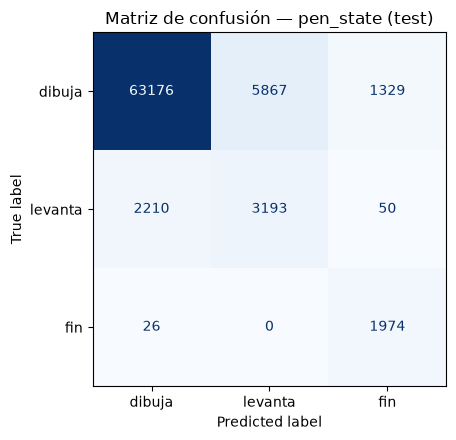

Puntos reales evaluados: 77,825 | pérdida test -> NLL 0.0476, CE 0.3294, compuesta 0.3770


In [21]:
@torch.no_grad()
def evaluate_split(
    model: SketchRNN,
    loader: DataLoader,
    cfg: TrainConfig,
    class_weights: torch.Tensor,
    device: torch.device,
    std_x: float,
    std_y: float,
) -> tuple[dict[str, Any], np.ndarray, np.ndarray]:
    """Métricas pooled (por punto) sobre un split completo, con máscara."""
    model.eval()
    pred_xy_parts: list[np.ndarray] = []
    true_xy_parts: list[np.ndarray] = []
    pred_pen_parts: list[np.ndarray] = []
    true_pen_parts: list[np.ndarray] = []
    reg_sum = pen_sum = 0.0
    n_points = 0

    for x, y, lengths in loader:
        x = x.to(device)
        y = y.to(device)
        lengths = lengths.to(device)
        mask = length_mask(lengths)
        params, pen_logits, _ = model(x)
        _, reg_loss, pen_loss, _, _ = composite_loss(
            params, pen_logits, y, mask, class_weights, cfg.pen_loss_weight
        )
        batch_points = int(mask.sum())
        n_points += batch_points
        reg_sum += reg_loss.item() * batch_points
        pen_sum += pen_loss.item() * batch_points

        pred_x = (params.pi * params.mu_x).sum(LAST_DIM)
        pred_y = (params.pi * params.mu_y).sum(LAST_DIM)
        pred_xy_parts.append(torch.stack([pred_x, pred_y], dim=LAST_DIM)[mask].cpu().numpy())
        true_xy_parts.append(y[..., S5_XY_SLICE][mask].cpu().numpy())
        pred_pen_parts.append(pen_logits.argmax(LAST_DIM)[mask].cpu().numpy())
        true_pen_parts.append(y[..., PEN_STATE_SLICE].argmax(LAST_DIM)[mask].cpu().numpy())

    pred_xy = np.concatenate(pred_xy_parts)
    true_xy = np.concatenate(true_xy_parts)
    pred_pen = np.concatenate(pred_pen_parts).astype(np.int64)
    true_pen = np.concatenate(true_pen_parts).astype(np.int64)

    mse_x = float(((pred_xy[:, DX_COL] - true_xy[:, DX_COL]) ** 2).mean())
    mse_y = float(((pred_xy[:, DY_COL] - true_xy[:, DY_COL]) ** 2).mean())
    mse_xy = 0.5 * (mse_x + mse_y)
    f1_macro = float(
        f1_score(
            true_pen,
            pred_pen,
            labels=list(range(NUM_PEN_STATES)),
            average="macro",
            zero_division=0,
        )
    )
    f1_per_class = np.asarray(
        f1_score(
            true_pen,
            pred_pen,
            labels=list(range(NUM_PEN_STATES)),
            average=None,
            zero_division=0,
        ),
        dtype=float,
    )
    cm = confusion_matrix(true_pen, pred_pen, labels=list(range(NUM_PEN_STATES)))
    support = np.bincount(true_pen, minlength=NUM_PEN_STATES)

    metrics = {
        "n_points": n_points,
        "mse_x_norm": mse_x,
        "mse_y_norm": mse_y,
        "mse_xy_norm": mse_xy,
        "mse_loss_norm": mse_x + mse_y,
        "mse_x_px": mse_x * std_x * std_x,
        "mse_y_px": mse_y * std_y * std_y,
        "mse_xy_px": 0.5 * (mse_x * std_x * std_x + mse_y * std_y * std_y),
        "f1_macro": f1_macro,
        "f1_per_class": {CLASS_NAMES[i]: float(v) for i, v in enumerate(f1_per_class)},
        "support": {CLASS_NAMES[i]: int(v) for i, v in enumerate(support)},
        "confusion_matrix": cm.astype(int).tolist(),
        "loss_reg": reg_sum / n_points,
        "loss_pen": pen_sum / n_points,
        "loss_composite": (reg_sum + cfg.pen_loss_weight * pen_sum) / n_points,
    }
    return metrics, true_pen, pred_pen


test_metrics, true_pen_test, pred_pen_test = evaluate_split(
    model,
    test_loader,
    TRAIN_CONFIG,
    CLASS_WEIGHTS,
    device,
    STD_X,
    STD_Y,
)
assert test_metrics["n_points"] == int(L_test.sum()), "la máscara de test no cuadra"

model_row = {
    "MSE Δx (norm)": test_metrics["mse_x_norm"],
    "MSE Δy (norm)": test_metrics["mse_y_norm"],
    "MSE media (norm)": test_metrics["mse_xy_norm"],
    "MSE Δx (px²)": test_metrics["mse_x_px"],
    "MSE Δy (px²)": test_metrics["mse_y_px"],
    "MSE media (px²)": test_metrics["mse_xy_px"],
    "F1 macro": test_metrics["f1_macro"],
    "Pérdida compuesta": test_metrics["loss_composite"],
}
model_table = pd.DataFrame({"Valor": model_row})
display(model_table.style.format("{:.4f}").set_caption("Métricas del modelo en test"))

per_class = pd.DataFrame(
    {
        "F1": test_metrics["f1_per_class"],
        "Soporte": test_metrics["support"],
    }
)
display(
    per_class.style.format({"F1": "{:.4f}", "Soporte": "{:,}"}).set_caption("F1 por clase en test")
)

print("Reporte de clasificación (test):\n")
print(
    classification_report(
        true_pen_test,
        pred_pen_test,
        labels=list(range(NUM_PEN_STATES)),
        target_names=CLASS_NAMES,
        zero_division=0,
        digits=4,
    )
)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay.from_predictions(
    true_pen_test,
    pred_pen_test,
    labels=list(range(NUM_PEN_STATES)),
    display_labels=CLASS_NAMES,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title("Matriz de confusión — pen_state (test)")
plt.tight_layout()
plt.show()
print(
    f"Puntos reales evaluados: {test_metrics['n_points']:,} | "
    f"pérdida test -> NLL {test_metrics['loss_reg']:.4f}, "
    f"CE {test_metrics['loss_pen']:.4f}, "
    f"compuesta {test_metrics['loss_composite']:.4f}"
)

# 9. Generación de ejemplos

Los bocetos se generan un punto a la vez: se parte de `S0 = (0, 0, 1, 0, 0)`, el modelo predice el siguiente punto, ese punto vuelve a entrar como entrada, y así hasta que predice "fin" o se llegan a 200 puntos.

- **Movimiento (Δx, Δy):** el modelo propone 20 movimientos posibles con su probabilidad. Usamos el **promedio ponderado** de todos, `E[Δ] = Σ πk μk`, que minimiza el MSE.
- **Estado del lápiz (`pen_state`):** se elige al azar con `softmax(logits / T)` y **T = 0.5**, para que cada manzana salga distinta. Antes se quita el sesgo de los pesos de clase, porque si no el modelo termina demasiado pronto y los dibujos salen cortos.

Probamos otras opciones con el mismo modelo entrenado: elegir el movimiento al azar daba líneas quebradas, y `argmax` en `pen_state` daba trazos uniformes pero casi sin variedad entre dibujos. Nos quedamos con el promedio de la mezcla y `pen_state` muestreado con T = 0.5, con dibujos limpios y distintos entre sí.

Con esa combinación salen 37.2 puntos y 2.8 trazos de media (real: 37.9 y 2.7). Al final se des-normaliza con `STD_X` y `STD_Y`, se pasa a stroke-3 y se guardan los PNG en `OUT_DIR`.

,puntos,terminó,trazos
i,,,
1,37,True,3
2,37,True,4
3,35,True,2
4,33,True,3
5,38,True,3
6,43,True,2


Se guardaron 6 PNG en salidas/boceto_generado_apple_*.png


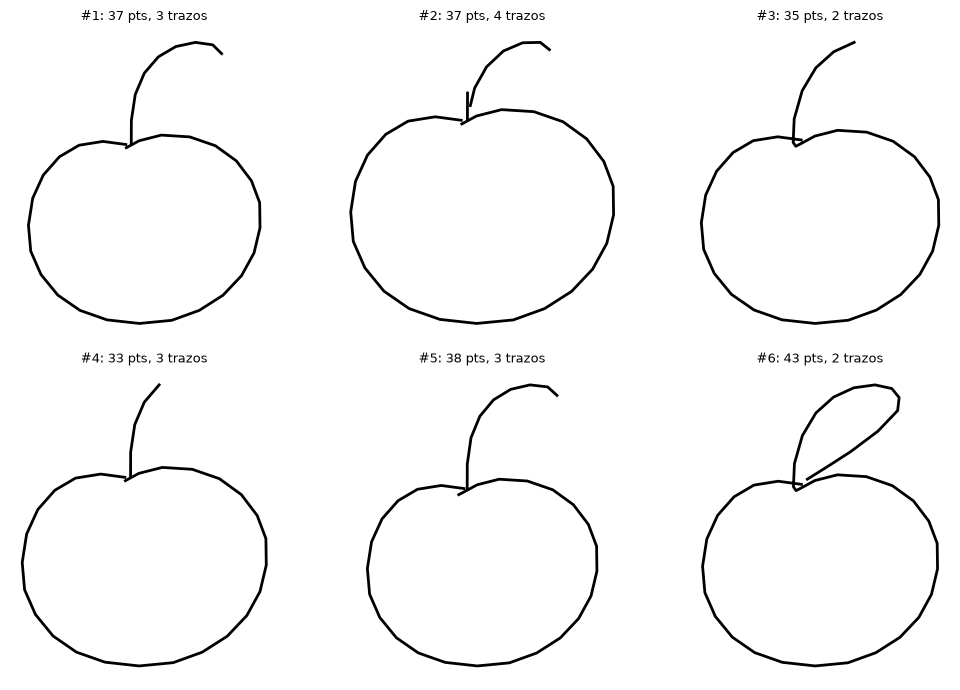

In [22]:
def stroke5_to_stroke3(stroke5: np.ndarray, std_x: float, std_y: float) -> np.ndarray:
    """Des-normaliza y pasa al formato stroke-3 que consume render_sketch."""
    stroke3 = np.zeros((len(stroke5), 3), dtype=np.float64)
    stroke3[:, DX_COL] = stroke5[:, S5_DX_COL] * std_x
    stroke3[:, DY_COL] = stroke5[:, S5_DY_COL] * std_y
    stroke3[:, PEN_LIFT_COL] = stroke5[:, S5_LIFT_COL]
    end_positions = stroke5[:, S5_END_COL] > 0.5
    stroke3[end_positions, DX_COL] = 0.0
    stroke3[end_positions, DY_COL] = 0.0
    stroke3[-1, PEN_LIFT_COL] = 1.0
    return stroke3


GENERATION_SEED = SEED + 1
GENERATION_TEMPERATURE = TRAIN_CONFIG.generation_temperature
N_GENERATIONS = TRAIN_CONFIG.n_generations

torch.manual_seed(GENERATION_SEED)
generated_strokes: list[np.ndarray] = []
generation_rows: list[dict[str, object]] = []
for i in range(1, N_GENERATIONS + 1):
    generated5 = generate_sketch(
        model,
        max_len=MAX_LEN,
        temperature=GENERATION_TEMPERATURE,
        device=device,
        delta_mode="mean",
        debias=True,
        class_weights=CLASS_WEIGHTS,
    )
    stroke3 = stroke5_to_stroke3(generated5, STD_X, STD_Y)
    path = OUT_DIR / f"boceto_generado_{CATEGORY}_{i}.png"
    render_sketch(stroke3, path)
    generated_strokes.append(stroke3)
    generation_rows.append(
        {
            "i": i,
            "puntos": len(generated5),
            "terminó": bool(generated5[-1, S5_END_COL] > 0.5),
            "trazos": int(generated5[:, S5_LIFT_COL].sum()) + 1,
        }
    )

generation_table = pd.DataFrame(generation_rows).set_index("i")
display(generation_table)
print(f"Se guardaron {N_GENERATIONS} PNG en {OUT_DIR}/boceto_generado_{CATEGORY}_*.png")

n_cols = 3
n_rows = math.ceil(N_GENERATIONS / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3.5 * n_cols, 3.5 * n_rows), squeeze=False)
for ax, stroke3, row in zip(
    axes.ravel()[:N_GENERATIONS], generated_strokes, generation_rows, strict=True
):
    draw_sketch(ax, stroke3)
    ax.set_title(f"#{row['i']}: {row['puntos']} pts, {row['trazos']} trazos", fontsize=9)
for ax in axes.ravel()[N_GENERATIONS:]:
    ax.axis("off")
fig.tight_layout()
plt.show()

# 10. Conclusiones

**Resultados.** El modelo se seleccionó por la menor pérdida de validación (época 60, pérdida 0.3785) y se evaluó
**una sola vez** sobre los 2.000 bocetos de prueba, aplicando la máscara de padding y agregando por punto
(77.825 puntos reales). 
* Resultados en test:

| Métrica | Valor |
|---|---:|
| MSE de Δx | 0.3760 (288.23 px²) |
| MSE de Δy | 0.3420 (361.53 px²) |
| MSE medio (Δx, Δy) | **0.3590** (324.88 px²) |
| F1 macro de `pen_state` | **0.7027** |
| F1 dibuja | 0.9305 |
| F1 levanta | 0.4400 |
| F1 fin | 0.7375 |
| Pérdida compuesta | **0.3770** (NLL 0.0476 + CE ponderada 0.3294) |

Los MSE están en unidades normalizadas, con su equivalente en px² entre paréntesis.

**Sobreajuste y regularización.** La pérdida de entrenamiento (calculada con aumento de datos y dropout) fue 0.4606
en la época 60, frente a 0.3785 en validación. Como el aumento de datos hace más difícil el problema de
entrenamiento, esa diferencia no indica por sí sola sobreajuste; la evidencia usada es la curva de validación, que se
mantuvo estable y aún mejorando al final. Se completaron las 60 épocas máximas; la mejor validación fue la última
época, así que se verificó si un presupuesto mayor ayudaba. Se repitió el entrenamiento con la misma arquitectura,
configuración y semilla hasta 120 épocas ( sus primeras 60 épocas coinciden
bit a bit con la referencia externa de 60). La validación siguió bajando: mejor época 119 y pérdida 0.3340 frente a
0.4269 en 60 (−21.8 %). Sin embargo, las métricas obligatorias apenas cambiaron: MSE medio 0.3627 → 0.3619 (−0.23 %)
y F1 macro 0.7000 → 0.7015 (+0.22 %). Casi toda la mejora de la pérdida compuesta (0.4239 → 0.3315) vino de la NLL
(0.0907 → −0.0005; una NLL ligeramente negativa es válida para densidades continuas), no de mejores medias
predichas. Las últimas 10 épocas fueron una meseta ruidosa: el mínimo fue la 119, la 120 empeoró y la tasa de
aprendizaje ya estaba en 2e-6. Por eso se mantiene el presupuesto de 60 épocas: entrenar más mejora la calibración de
la densidad, no las métricas que pide el enunciado.

| métrica (60 → 120) | 60 épocas | 120 épocas |
|---|---:|---:|
| mejor época | 58 | 119 |
| pérdida de validación | 0.4269 | 0.3340 |
| MSE medio (norm.) | 0.3627 | 0.3619 |
| F1 macro | 0.7000 | 0.7015 |
| pérdida compuesta | 0.4239 | 0.3315 |

La comparación 60 vs 120 usa la corrida externa con batch de evaluación 512; la corrida propia del notebook (60
épocas, batch 256) tiene métricas ligeramente distintas (MSE 0.3590, F1 0.7027, pérdida 0.3770). Frente a esa corrida,
el modelo de 120 no mejora MSE/F1; solo baja la pérdida por NLL. Contribuyen a controlar el sobreajuste el dropout 0.2,
el *weight decay* 1e-5, el escalado aleatorio [0.85, 1.15] de Δx y Δy, el recorte de gradientes a 5.0 y la reducción
de la tasa de aprendizaje cuando la validación se estanca. La selección de época se hizo únicamente con validación;
prueba no participó en ninguna decisión.

**Generación.** Se generaron 6 bocetos con temperatura 0.5, usando la **media de la mezcla** `E[Δ] = Σ πk μk` para
(Δx, Δy) y `pen_state` muestreado con **corrección del sesgo de los pesos de clase**. Los 6 terminaron por predecir
"fin" antes de los 200 puntos (longitudes entre 33 y 43, media 37.2; 2–4 trazos, media 2.8; la mediana real es 37
puntos y la media de trazos 2.7). Los PNG están en `salidas/boceto_generado_apple_1..6.png`. Las 6 muestras tienen
contorno redondeado y tallo/hoja y son reconocibles como manzanas; las diferencias entre ellas son de proporción y
orientación, no artefactos. La media de la mezcla produce trazos mucho más limpios que muestrear componentes de la
mezcla; la corrección de pesos evita que el modelo sobre-prediga "fin" y acorte los dibujos. La elección se midió con
el mismo modelo entrenado: muestrear Δ daba líneas quebradas; media + T = 0.5 + corrección daba ~37 puntos y ~2.8 trazos.

**Limitaciones.** Los resultados corresponden a **una sola semilla** (42) y a una sola categoría (`apple`); no se
reporta media ± desviación entre semillas. La verificación de 120 épocas también usó una sola semilla. El modelo se entrenó con 16.000 bocetos y secuencias truncadas a 200
puntos, como exige el enunciado. La evaluación es a un paso (*teacher forcing*), mientras que la generación es
autorregresiva y sufre *exposure bias*: pequeños errores se acumulan y pueden desviar el dibujo. El aumento de datos
se limita a un escalado independiente de Δx y Δy; no se exploraron rotaciones ni otras arquitecturas. La MDN modela la
multimodalidad del siguiente punto, pero el MSE obligatorio y la generación usan la media de la mezcla, no una muestra;
por eso la diversidad entre bocetos es menor. Con `delta_mode="sample"` se puede recuperar más variedad a costa de
trazos más ruidosos (se midió: muestrear Δ producía líneas quebradas). Finalmente, no se hizo una búsqueda exhaustiva
de hiperparámetros: se fijaron valores estándar y se validaron con la curva de validación, que es lo que permite el
presupuesto de cómputo.

### Evidencia: curvas de la corrida de 120 épocas

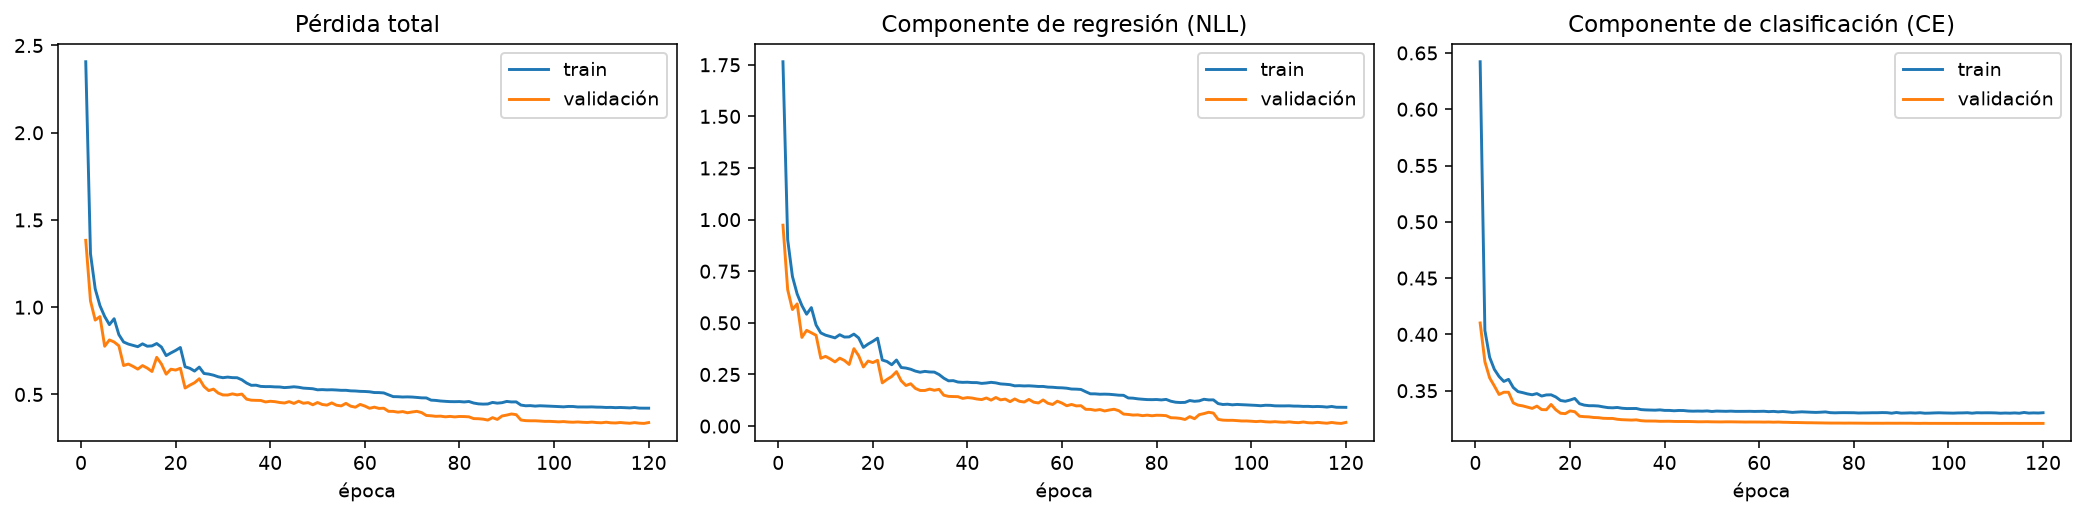

_Corrida de verificación externa con la misma arquitectura, configuración y semilla que el notebook (batch de evaluación 512). La pérdida de validación sigue bajando hasta la época 119 (mínimo
0.3340), mientras que el MSE medio y el F1 macro de test apenas cambian (−0.23 % y +0.22 %); casi toda la mejora de
la pérdida compuesta proviene de la NLL. Compárese con las curvas de 60 épocas de la sección 7._